# **Analisis Kinerja dan Perilaku Siswa/i Dengan Pendekatan Machine Learning**         
## Disusun oleh:


1.   Chrisustomus Boimau
2.   Paulina Devina Wijaya
3.   Reuben Zachary Susanto

****

# **Tugas-tugas utama**


1.   **Klasifikasi** - Mengidentifikasi parent_education_level untuk setiap siswa


*   Output    : high-school, diploma, master, PHD
*   Algoritma : Random Forest dan XGBoost


2.   **Prediksi** - Prediksi nilai akhir siswa dan prediksi tingkat stres siswa


*   Output    : (1) Nilai akhir siswa dan (2) tingkat stres siswa
*   Algoritma : Linear Regression, Polynomial Regression, dan Random Forest Regressor

3.   **Klustering** - Mengidentifikasi kelompok performa siswa berdasarkan sejumlah fitur akademik dan perilaku

*   Output    : Berkinerja tinggi, berkinerja biasa, dan sedang berjuang
*   Algoritma : K-Means Clustering dan DBSCAN




# **Future Works**
1.   **Klasifikasi** - mengidentifikasikan siswa/i yang berpotensi untuk dropout dan siswa/i yang berpotensi mengalami stress tinggi.*

*   Output    : 1 / 0
*   Algoritma : Isolation Forest dan LOF (*Local Outlier Factor*)

*Jika waktu memperbolehkan

****



*Import Necessary Libraries*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, recall_score, precision_score, roc_auc_score, roc_curve, classification_report, mean_squared_error, silhouette_score
from sklearn.feature_selection import RFE, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.naive_bayes import GaussianNB, BernoulliNB, MultinomialNB
from sklearn.impute import KNNImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.base import clone

import warnings
warnings.filterwarnings('ignore')

# *Data Reading*

In [2]:
try:
  main_df = pd.read_csv('Students_Grading_Dataset.csv')
except FileNotFoundError:
  print(f"The file is not imported yet. Import the file first.")
else:
  row, col = main_df.shape
  print(f"There are {row} datas with {col} features.")

There are 5000 datas with 23 features.


In [3]:
# Print the features
print("\n".join(main_df.columns.to_list()))

Student_ID
First_Name
Last_Name
Email
Gender
Age
Department
Attendance (%)
Midterm_Score
Final_Score
Assignments_Avg
Quizzes_Avg
Participation_Score
Projects_Score
Total_Score
Grade
Study_Hours_per_Week
Extracurricular_Activities
Internet_Access_at_Home
Parent_Education_Level
Family_Income_Level
Stress_Level (1-10)
Sleep_Hours_per_Night


In [4]:
main_df.head()

,Student_ID,First_Name,Last_Name,Email,Gender,Age,Department,Attendance (%),Midterm_Score,Final_Score,...,Projects_Score,Total_Score,Grade,Study_Hours_per_Week,Extracurricular_Activities,Internet_Access_at_Home,Parent_Education_Level,Family_Income_Level,Stress_Level (1-10),Sleep_Hours_per_Night
0,S1000,Omar,Williams,student0@university.com,Female,22,Engineering,52.29,55.03,57.82,...,85.90,56.09,F,6.2,No,Yes,High School,Medium,5,4.7
1,S1001,Maria,Brown,student1@university.com,Male,18,Engineering,97.27,97.23,45.80,...,55.65,50.64,A,19.0,No,Yes,NaN,Medium,4,9.0
2,S1002,Ahmed,Jones,student2@university.com,Male,24,Business,57.19,67.05,93.68,...,73.79,70.30,D,20.7,No,Yes,Master's,Low,6,6.2
3,S1003,Omar,Williams,student3@university.com,Female,24,Mathematics,95.15,47.79,80.63,...,92.12,61.63,A,24.8,Yes,Yes,High School,High,3,6.7
4,S1004,John,Smith,student4@university.com,Female,23,CS,54.18,46.59,78.89,...,68.42,66.13,F,15.4,Yes,Yes,High School,High,2,7.1


# *Exploratory Data Analysis (EDA)*
Catatan: Akan dilakukan minimal 5 EDA untuk mengetahui konteks data.

## **Melihat Informasi Dasar Dataset**

Disini, kami ingin mengetahui isi dari dataset yang kami unggah dari platform Kaggle, seperti tipe datanya apa, dan berapa banyak data bersifat non-null di dataset ini.

In [5]:
main_df.info()
main_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  5000 non-null   object 
 1   First_Name                  5000 non-null   object 
 2   Last_Name                   5000 non-null   object 
 3   Email                       5000 non-null   object 
 4   Gender                      5000 non-null   object 
 5   Age                         5000 non-null   int64  
 6   Department                  5000 non-null   object 
 7   Attendance (%)              4484 non-null   float64
 8   Midterm_Score               5000 non-null   float64
 9   Final_Score                 5000 non-null   float64
 10  Assignments_Avg             4483 non-null   float64
 11  Quizzes_Avg                 5000 non-null   float64
 12  Participation_Score         5000 non-null   float64
 13  Projects_Score              5000 

,Student_ID,First_Name,Last_Name,Email,Gender,Age,Department,Attendance (%),Midterm_Score,Final_Score,...,Projects_Score,Total_Score,Grade,Study_Hours_per_Week,Extracurricular_Activities,Internet_Access_at_Home,Parent_Education_Level,Family_Income_Level,Stress_Level (1-10),Sleep_Hours_per_Night
0,S1000,Omar,Williams,student0@university.com,Female,22,Engineering,52.29,55.03,57.82,...,85.90,56.09,F,6.2,No,Yes,High School,Medium,5,4.7
1,S1001,Maria,Brown,student1@university.com,Male,18,Engineering,97.27,97.23,45.80,...,55.65,50.64,A,19.0,No,Yes,NaN,Medium,4,9.0
2,S1002,Ahmed,Jones,student2@university.com,Male,24,Business,57.19,67.05,93.68,...,73.79,70.30,D,20.7,No,Yes,Master's,Low,6,6.2
3,S1003,Omar,Williams,student3@university.com,Female,24,Mathematics,95.15,47.79,80.63,...,92.12,61.63,A,24.8,Yes,Yes,High School,High,3,6.7
4,S1004,John,Smith,student4@university.com,Female,23,CS,54.18,46.59,78.89,...,68.42,66.13,F,15.4,Yes,Yes,High School,High,2,7.1


## **Statistik Deskriptif**

Pada bagian ini, kami ingin mengetahui statistik dari setiap kolom yang ada. Kami menampilkan jumlah, rata-rata, standar deviasi, minimum, index quartil, dan maksimum dari dataset ini.

In [6]:
main_df.describe()

,Age,Attendance (%),Midterm_Score,Final_Score,Assignments_Avg,Quizzes_Avg,Participation_Score,Projects_Score,Total_Score,Study_Hours_per_Week,Stress_Level (1-10),Sleep_Hours_per_Night
count,5000.000000,4484.000000,5000.000000,5000.000000,4483.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000
mean,21.048400,75.431409,70.326844,69.640788,74.798673,74.910728,4.980024,74.924860,75.121804,17.658860,5.48080,6.488140
std,1.989786,14.372446,17.213209,17.238744,14.411799,14.504281,2.890136,14.423415,14.399941,7.275864,2.86155,1.452283
min,18.000000,50.010000,40.000000,40.000000,50.000000,50.030000,0.000000,50.010000,50.020000,5.000000,1.00000,4.000000
25%,19.000000,63.265000,55.457500,54.667500,62.090000,62.490000,2.440000,62.320000,62.835000,11.400000,3.00000,5.200000
50%,21.000000,75.725000,70.510000,69.735000,74.810000,74.695000,4.955000,74.980000,75.395000,17.500000,5.00000,6.500000
75%,23.000000,87.472500,84.970000,84.500000,86.970000,87.630000,7.500000,87.367500,87.652500,24.100000,8.00000,7.700000
max,24.000000,100.000000,99.980000,99.980000,99.980000,99.960000,10.000000,100.000000,99.990000,30.000000,10.00000,9.000000


## **Korelasi Antar Fitur**

Pada bagian ini, kami ingin mengetahui seberapa besar korelasi antar fitur di dataset ini. Kami menggunakan matrix correlation, dan kami visualisasikan sebagai heatmap agar bisa melihat lebih jelas korelasi antar fitur tersebut. 

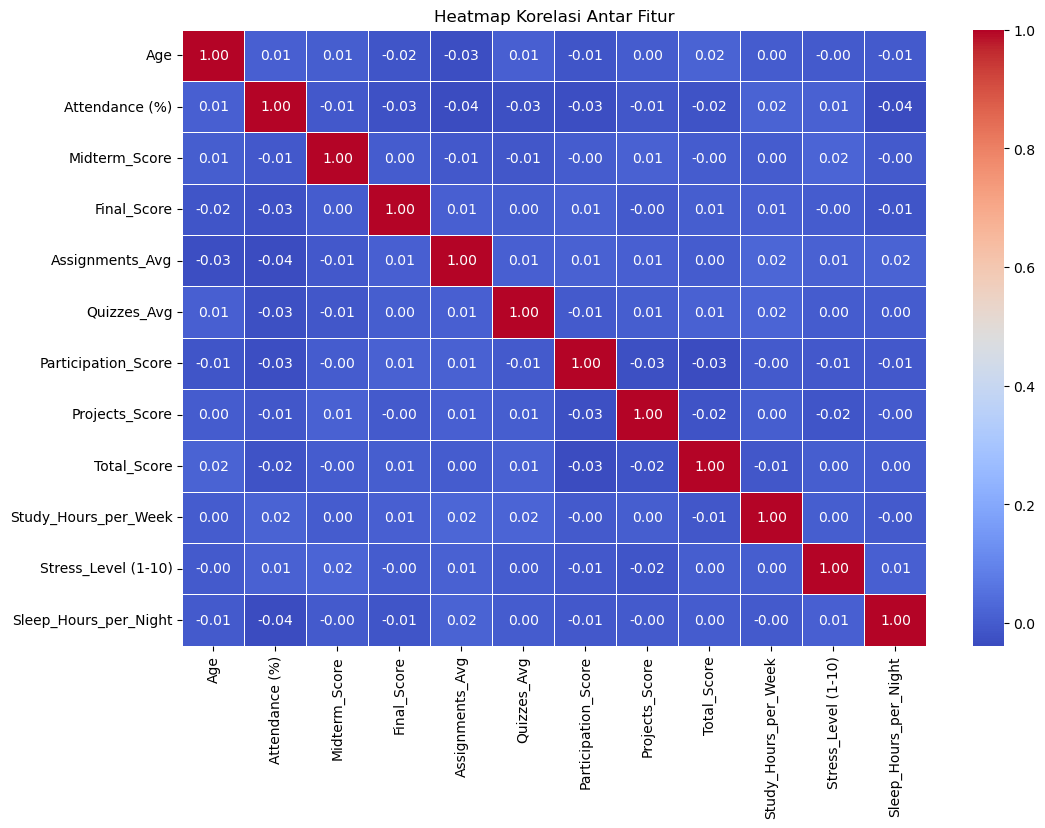

In [7]:
# Memilih hanya kolom numerik
numeric_df = main_df.select_dtypes(include=['number'])

# Menghitung korelasi antar fitur
correlation_matrix = numeric_df.corr()

# Visualisasi korelasi dengan heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Heatmap Korelasi Antar Fitur")
plt.show()


Heatmap ini menunjukkan korelasi antara berbagai fitur akademik dan kebiasaan mahasiswa. Dari grafik, terlihat bahwa sebagian besar korelasi antar fitur sangat rendah (mendekati nol), menunjukkan bahwa tidak ada hubungan linear yang kuat antara variabel-variabel ini. Nilai korelasi yang tinggi hanya muncul pada diagonal utama karena setiap fitur memiliki korelasi sempurna (1.0) dengan dirinya sendiri.

# *Kumpulan Grafik*

## **All Distribution, Scatterplot and Boxplot**

In [8]:
def optimal_bins(df, column):
    data = df[column].dropna()
    q3, q1 = np.percentile(data, [75 ,25])
    iqr = q3 - q1
    bin_width = 2 * iqr * (len(data) ** (-1/3))

    if bin_width == 0:
        return 10

    bins = int(np.ceil((data.max() - data.min()) / bin_width))
    return max(bins, 1)

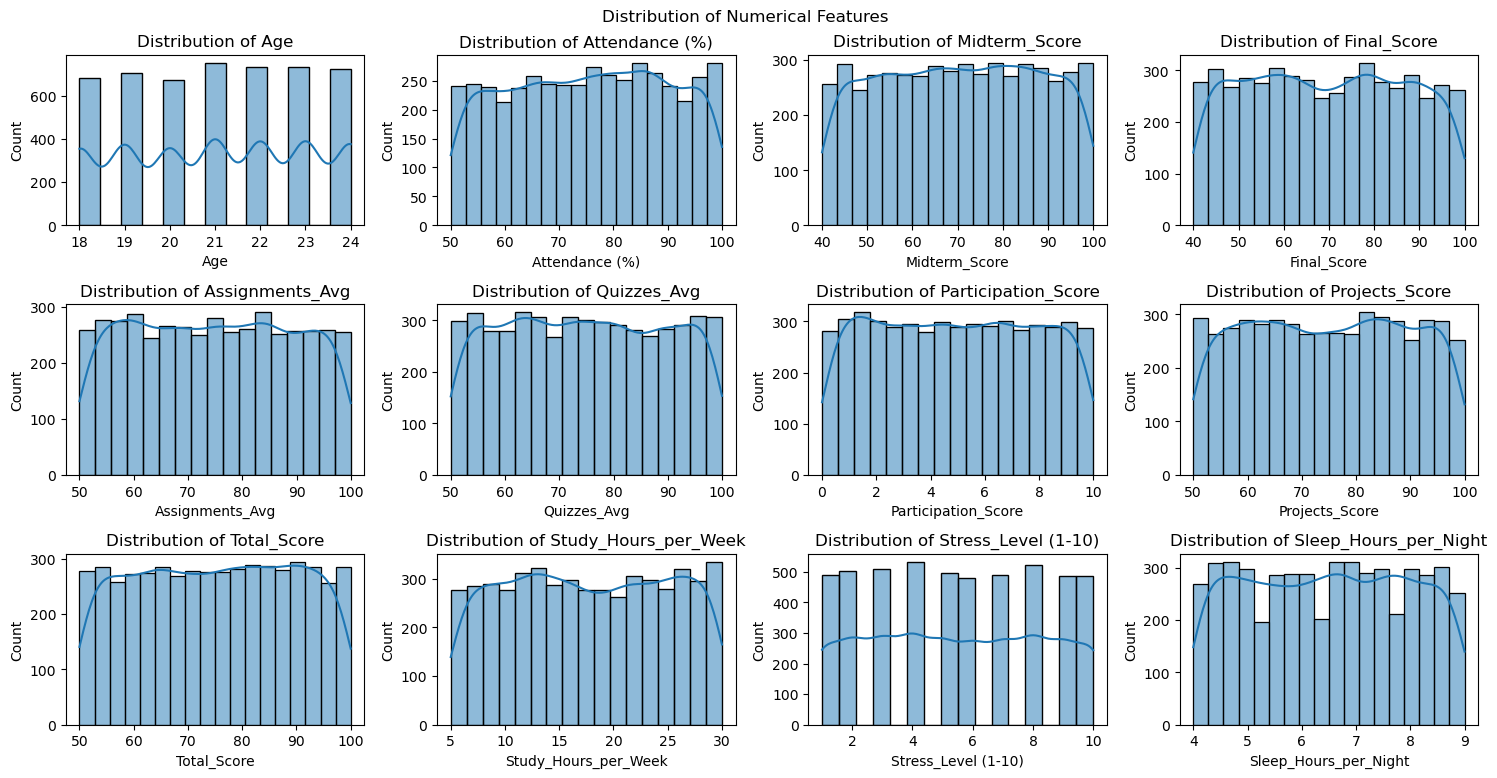

In [9]:
plt.figure(figsize=(15, 10))
for i, col in enumerate(numeric_df, 1):
    plt.subplot(4, 4, i)
    sns.histplot(numeric_df[col], bins=optimal_bins(numeric_df, col), kde=True)
    plt.title(f"Distribution of {col}")

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

Grafik di atas menunjukkan distribusi berbagai fitur berkaitan dengan data mahasiswa, seperti usia, kehadiran, nilai akademik, kebiasaan belajar, serta faktor gaya hidup. Mayoritas mahasiswa berusia antara 18–24 tahun dengan kehadiran antara 50-100%. Nilai midterm, final, tugas, kuis, dan proyek tersebar cukup merata antara 50–100. Skor partisipasi menunjukkan persebaran yang merata dari 0–10, sementara total skor pun menunjukkan pesebaran seimbang. Dari segi kebiasaan belajar, sebagian besar mahasiswa belajar 5–30 jam per minggu dan tidur 4–89 jam per malam. Tingkat stres cukup tersebar antara 0-10. Secara umum, grafik di atas menunjukan persebaran data yang uniform atau merata pada setiap bagiannya.

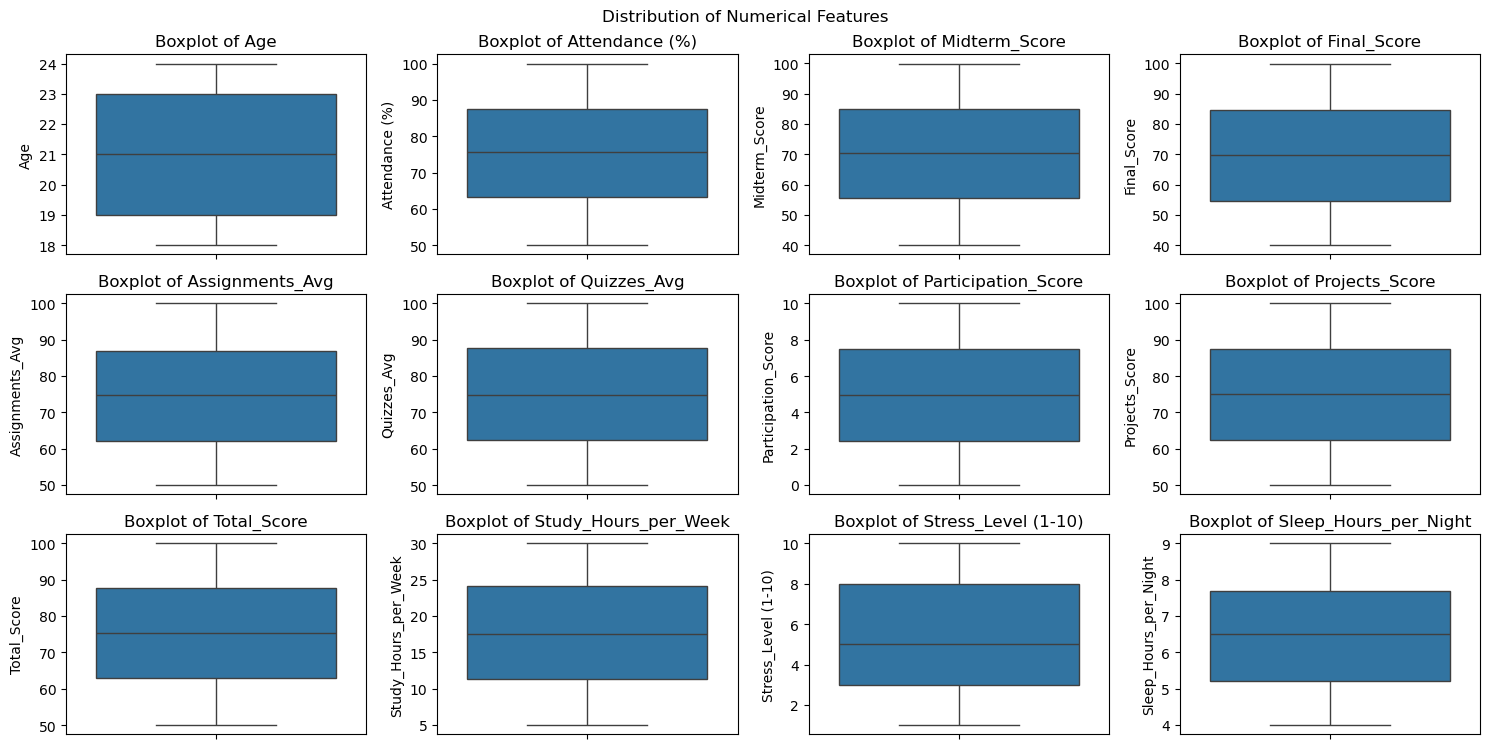

In [10]:
plt.figure(figsize=(15, 10))
for i, col in enumerate(numeric_df, 1):
    plt.subplot(4, 4, i)
    sns.boxplot(y=numeric_df[col])
    plt.title(f"Boxplot of {col}")

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

Berdasarkan visualisasi boxplot pada berbagai fitur numerik mahasiswa, dapat dilihat bahwa setiap fitur tidak memiliki pencilan. Ketidakhadiran pencilan ini menunjukkan bahwa data pada fitur-fitur tersebut memiliki distribusi yang stabil dan relatif homogen. Misalnya, usia mahasiswa berkisar antara 18 hingga 24 tahun, partisipasi di kelas berada dalam rentang yang konsisten antara 0 hingga 10, tingkat stres umumnya berada antara 2 hingga 10, dan jam tidur per malam berkisar antara 5 hingga 9 jam. Hal ini mengindikasikan bahwa sebagian besar mahasiswa dalam data ini memiliki karakteristik yang serupa dalam hal usia, partisipasi, stres, dan pola tidur,dan kriteria lainnya tanpa adanya nilai ekstrem yang menyimpang dari pola umum.

## **Histogram Age**

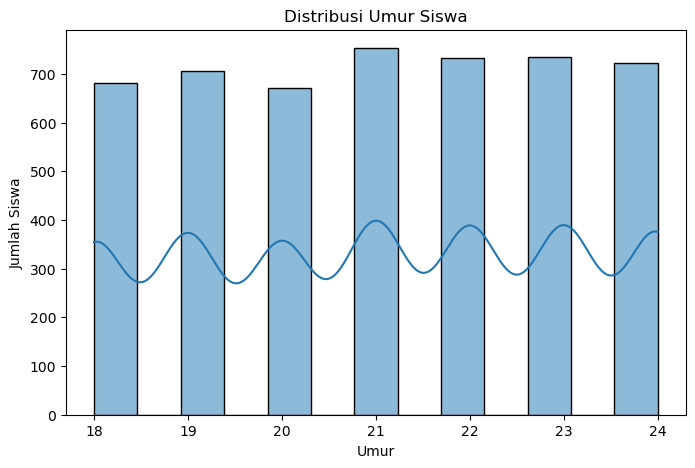

In [11]:
plt.figure(figsize=(8,5))
sns.histplot(main_df['Age'], bins=optimal_bins(main_df,'Age'), kde=True)
plt.title("Distribusi Umur Siswa")
plt.xlabel("Umur")
plt.ylabel("Jumlah Siswa")
plt.show()

**Ini berarti bahwa distribusi umur siswa dari range 18-24 tahun memiliki variasi yang tinggi.**

## **Histogram Participation Score**

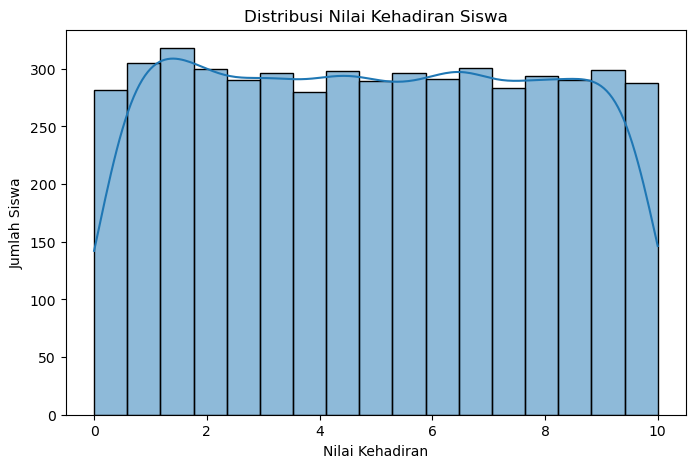

In [12]:
plt.figure(figsize=(8,5))
sns.histplot(main_df['Participation_Score'], bins=optimal_bins(main_df,'Participation_Score'), kde=True)
plt.title("Distribusi Nilai Kehadiran Siswa")
plt.xlabel("Nilai Kehadiran")
plt.ylabel("Jumlah Siswa")
plt.show()

**Grafik tersebut menunjukkan bahwa mayoritas siswa memiliki nilai kehadiran antara 1-9, dilihat dari trenlinenya**

## **Histogram Department**

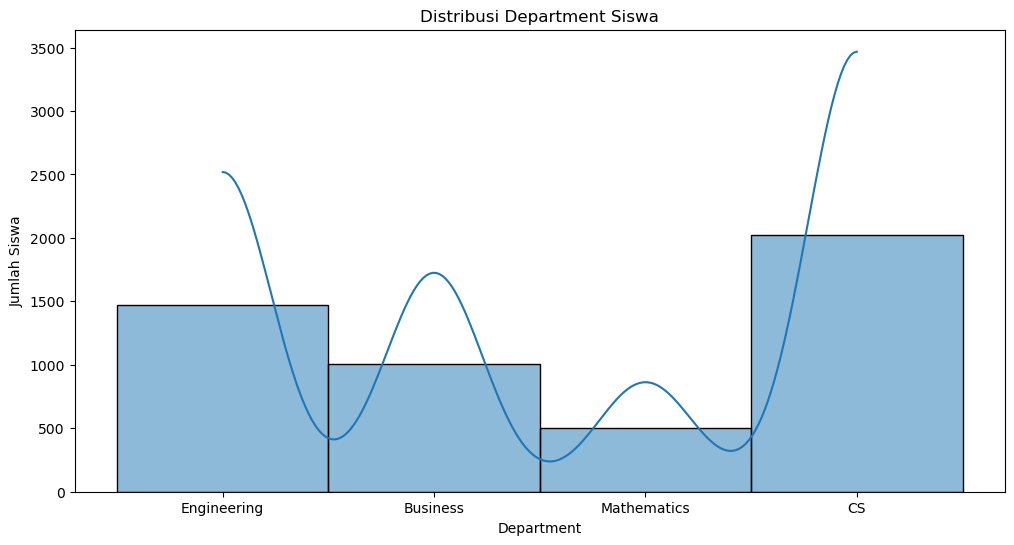

In [13]:
plt.figure(figsize=(12,6))
sns.histplot(main_df['Department'], bins=4, kde=True)
plt.title("Distribusi Department Siswa")
plt.xlabel("Department")
plt.ylabel("Jumlah Siswa")
plt.show()

**Grafik histogram menunjukkan bahwa mayoritas siswa berada dalam department CS (Computer Science). Sedangkan department dengan siswa paling sedikit adalah Mathematics**

## **Histogram Study Hours per Week**

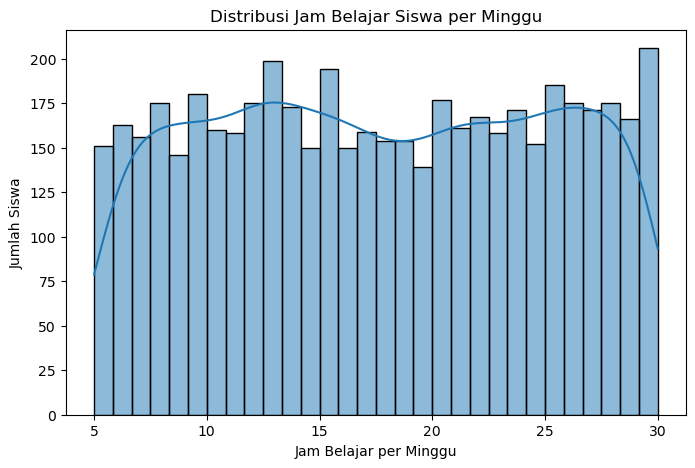

In [14]:
plt.figure(figsize=(8,5))
sns.histplot(main_df['Study_Hours_per_Week'], bins=30, kde=True)
plt.title("Distribusi Jam Belajar Siswa per Minggu")
plt.xlabel("Jam Belajar per Minggu")
plt.ylabel("Jumlah Siswa")
plt.show()

**Ini berarti, mayoritas siswa memiliki jam belajar di antara 8 sampai 28 (perkiraan)**

## **Histogram Stress Level**

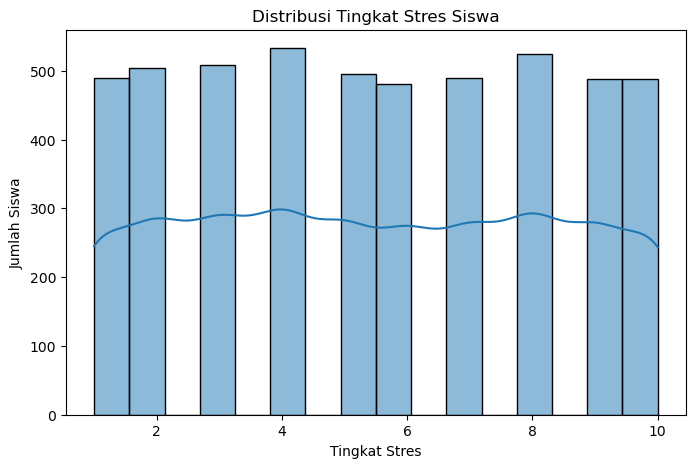

In [15]:
plt.figure(figsize=(8,5))
sns.histplot(main_df['Stress_Level (1-10)'], bins=optimal_bins(main_df,'Stress_Level (1-10)'), kde=True)
plt.title("Distribusi Tingkat Stres Siswa")
plt.xlabel("Tingkat Stres")
plt.ylabel("Jumlah Siswa")
plt.show()

terlihat bahwa jumlah siswa cukup merata di berbagai tingkat stres, tanpa adanya puncak signifikan pada satu tingkat tertentu. Pola distribusi yang hampir uniform menunjukkan bahwa tingkat stres bervariasi secara luas di antara siswa dengan beberapa fluktuasi kecil.

## **Histogram Attendance**

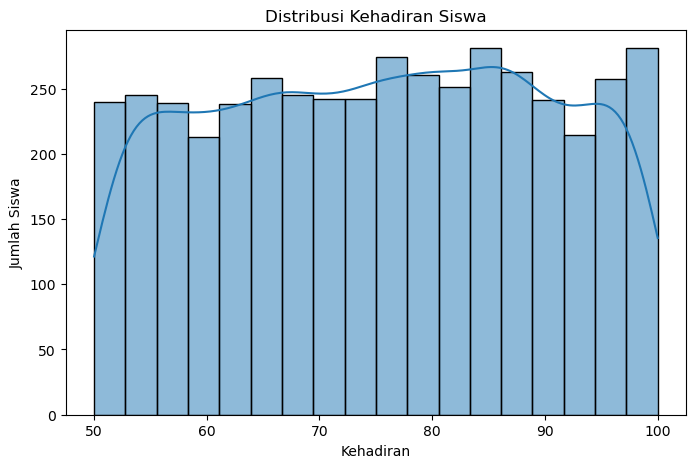

In [16]:
plt.figure(figsize=(8,5))
sns.histplot(main_df['Attendance (%)'], bins=optimal_bins(main_df,'Attendance (%)'), kde=True)
plt.title("Distribusi Kehadiran Siswa")
plt.xlabel("Kehadiran")
plt.ylabel("Jumlah Siswa")
plt.show()

Berdasarkan histogram distribusi kehadiran siswa, terlihat bahwa mayoritas siswa memiliki tingkat kehadiran yang cukup tinggi, yaitu berada pada rentang 50% hingga 100%. Pola distribusi ini cenderung menyerupai distribusi uniform. Selain itu, tidak terlihat adanya lonjakan ekstrem atau penyebaran yang sangat lebar, yang mengindikasikan bahwa kehadiran siswa cukup konsisten di antara populasi yang diamati.

## **Histogram Assignments_Avg**

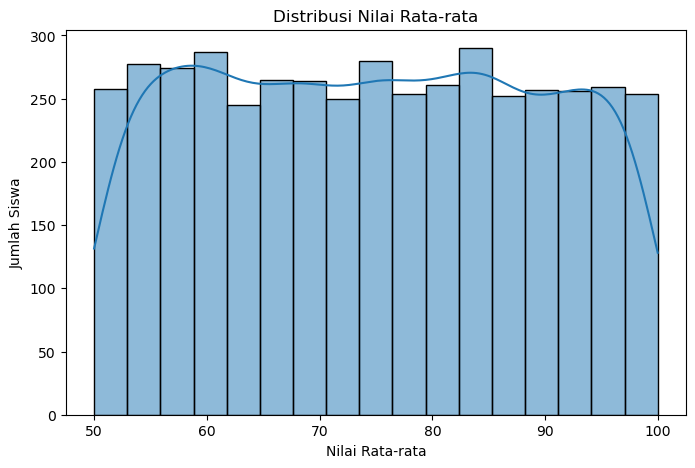

In [17]:
plt.figure(figsize=(8,5))
sns.histplot(main_df['Assignments_Avg'], bins=optimal_bins(main_df,'Assignments_Avg'), kde=True)
plt.title("Distribusi Nilai Rata-rata")
plt.xlabel("Nilai Rata-rata")
plt.ylabel("Jumlah Siswa")
plt.show()

Berdasarkan histogram distribusi nilai rata-rata, terlihat bahwa mayoritas siswa memiliki nilai rata-rata yang cukup menyebar secara merata, yaitu berada pada rentang 50 hingga 100. Pola distribusi ini cenderung menyerupai distribusi uniform. Selain itu, tidak terlihat adanya lonjakan ekstrem atau penyebaran yang sangat lebar, yang mengindikasikan bahwa kehadiran siswa cukup konsisten di antara populasi yang diamati.

## **Histogram Parent Education Level**

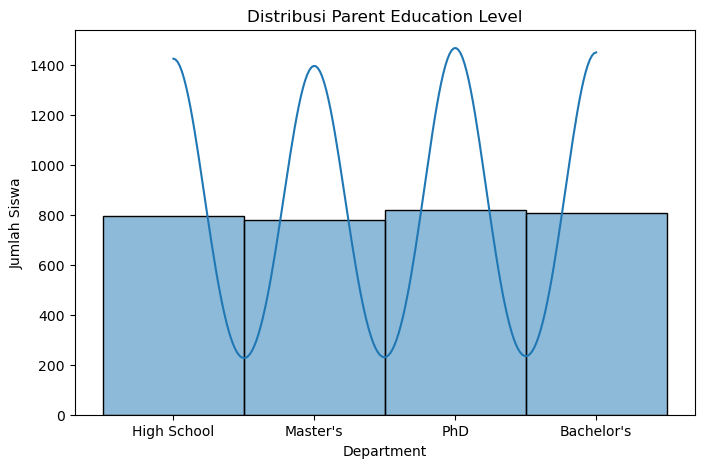

In [18]:
plt.figure(figsize=(8,5))
sns.histplot(main_df['Parent_Education_Level'], bins=4, kde=True)
plt.title("Distribusi Parent Education Level")
plt.xlabel("Department")
plt.ylabel("Jumlah Siswa")
plt.show()

Berdasarkan histogram distribusi nilai rata-rata, terlihat bahwa penyebaran level edukasi setiap orangtua cukup merata antara 750-850. dan histogram tersebut menunjukan distribusi yang hampir uniform.

## **Histogram Sleep Hours Per Night**

<Axes: xlabel='Sleep_Hours_per_Night', ylabel='Count'>

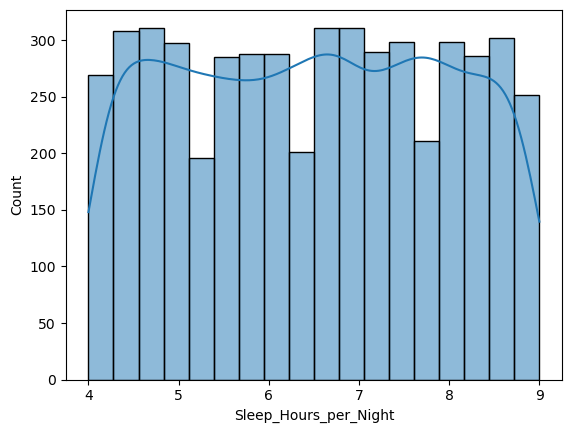

In [19]:
sns.histplot(main_df['Sleep_Hours_per_Night'], bins=optimal_bins(main_df,'Sleep_Hours_per_Night'), kde=True)

## **Boxplot Assignments_Avg vs Department**

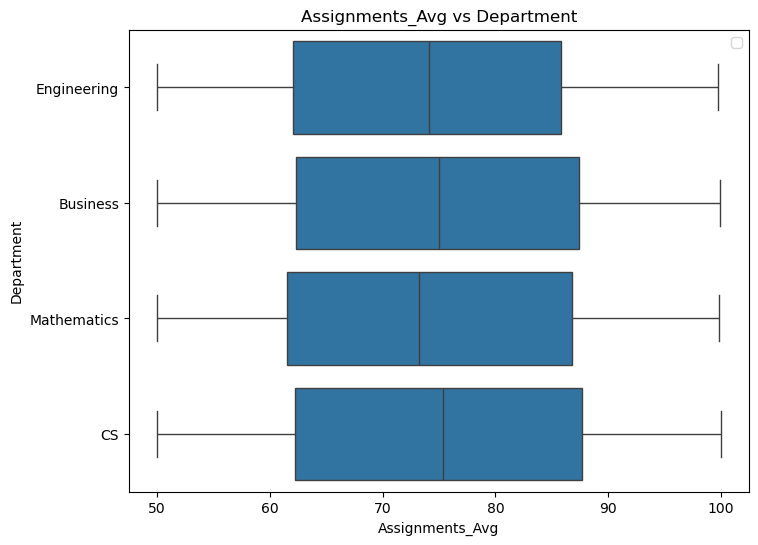

In [20]:
plt.figure(figsize=(8,6))
sns.boxplot(x='Assignments_Avg', y='Department', data=main_df)

plt.xlabel('Assignments_Avg')
plt.ylabel('Department')
plt.title('Assignments_Avg vs Department')

plt.legend()
plt.show()

Berdasarkan visualisasi boxplot rata-rata tugas mahasiswa pada berbagai departemen, dapat dilihat bahwa distribusi nilai pada setiap departemen tidak menunjukkan adanya pencilan. Ketidakhadiran pencilan ini menunjukkan bahwa data pada fitur nilai tugas memiliki distribusi yang stabil dan relatif homogen di seluruh departemen. Misalnya, rata-rata nilai tugas mahasiswa dari departemen Computer Science, Mathematics, Business, dan Engineering umumnya berada dalam rentang 60 hingga 90, dengan sebaran nilai yang konsisten.

## **Boxplot Attendance VS Total Score**

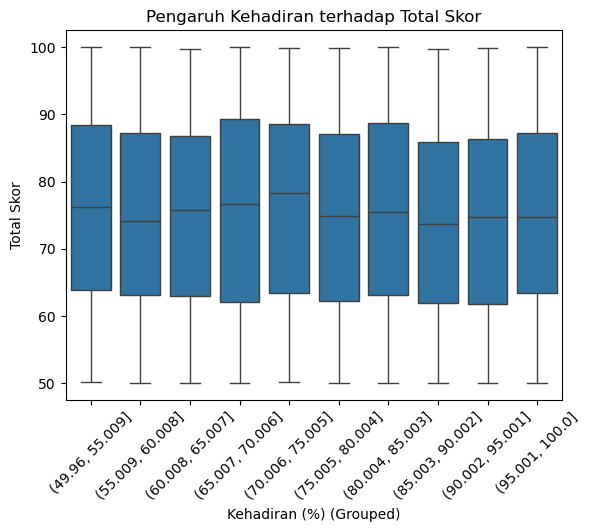

In [21]:
sns.boxplot(x=pd.cut(main_df['Attendance (%)'], bins=10), y=main_df['Total_Score'])
plt.xticks(rotation=45)
plt.title("Pengaruh Kehadiran terhadap Total Skor")
plt.xlabel("Kehadiran (%) (Grouped)")
plt.ylabel("Total Skor")
plt.show()

Berdasarkan visualisasi boxplot yang menunjukkan hubungan antara persentase kehadiran dan total skor mahasiswa, dapat dilihat bahwa setiap kelompok kehadiran tidak memiliki pencilan yang signifikan. Ketidakhadiran pencilan ini menunjukkan bahwa skor total mahasiswa pada tiap kelompok kehadiran memiliki distribusi yang stabil dan tidak menunjukkan adanya nilai ekstrem.

## **Boxplot Age vs Gender**

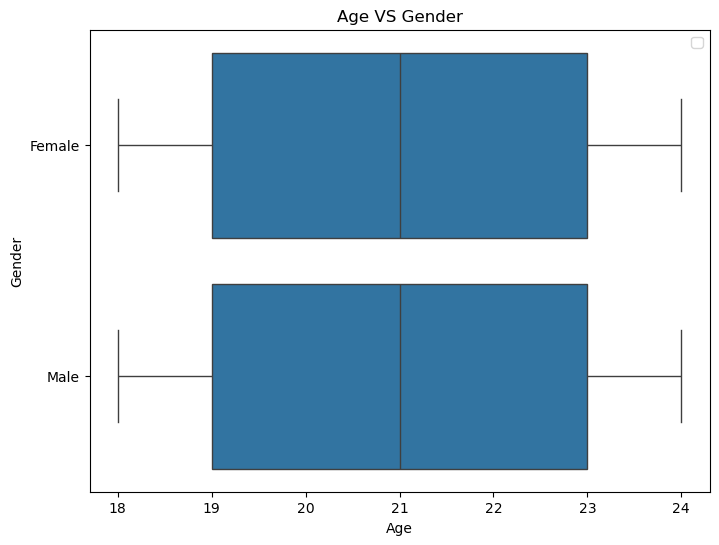

In [22]:
plt.figure(figsize=(8,6))
sns.boxplot(x='Age', y='Gender', data=main_df)

plt.xlabel('Age')
plt.ylabel('Gender')
plt.title('Age VS Gender')

plt.legend()
plt.show()

Berdasarkan visualisasi boxplot yang membandingkan usia berdasarkan gender, terlihat bahwa distribusi usia antara mahasiswa laki-laki dan perempuan relatif serupa. Kedua kelompok memiliki rentang usia yang sama, yaitu dari 18 hingga 24 tahun, serta median usia yang identik di sekitar usia 21 tahun. Tidak ditemukan pencilan pada kedua kelompok, yang menunjukkan bahwa usia mahasiswa dalam sampel ini cukup homogen, baik untuk laki-laki maupun perempuan. Kesamaan distribusi ini mengindikasikan bahwa usia tidak dipengaruhi oleh gender dalam data yang dianalisis.

## **Boxplot Total Score VS Stress levels**

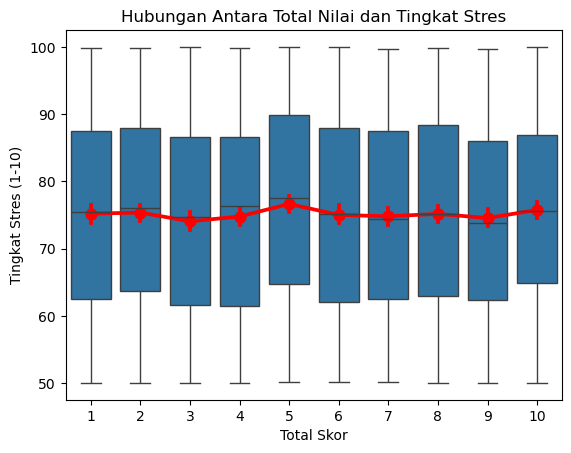

In [23]:
sns.boxplot(x='Stress_Level (1-10)', y='Total_Score', data=main_df)
sns.pointplot(x='Stress_Level (1-10)', y='Total_Score', data=main_df, color='red', estimator='mean', markers='o')
plt.title("Hubungan Antara Total Nilai dan Tingkat Stres")
plt.xlabel("Total Skor")
plt.ylabel("Tingkat Stres (1-10)")
plt.show()

Visualisasi ini menunjukkan hubungan antara total skor dengan tingkat stres mahasiswa. Setiap kotak pada boxplot mewakili distribusi tingkat stres untuk masing-masing nilai total, dari skor 1 hingga 10 terhadap suatu tingkat stress. Secara umum, rata-rata tingkat stres tampak relatif stabil di seluruh rentang skor. Hal ini mengindikasikan bahwa tidak terdapat hubungan yang kuat antara total nilai dengan tingkat stres. Artinya, baik mahasiswa dengan nilai rendah maupun tinggi cenderung mengalami tingkat stres yang serupa. Variasi dalam tingkat stres lebih dipengaruhi oleh faktor lain di luar total nilai.

# *Data Preprocessing (Data Cleaning, Feature Engineering)*
Catatan: Terdapat kemungkinan menggunakan machine learning untuk fitur *Parent Education Level* dan *Family income level* yang memiliki nilai null. Pikirkan juga kondisi datasetnya, seperti *class imbalance* dan *bias*. Konfirmasi di bagian EDA juga.

In [24]:
# Print any null values that exists
null_df = main_df.isnull().sum()
null_df[null_df > 0]

Attendance (%)             516
Assignments_Avg            517
Parent_Education_Level    1794
dtype: int64

There are 516 attendance value, 517 assignments average value and 1794 parent education level missing.

In [25]:
# To find out the types of data
main_df.dtypes[main_df.isnull().any()]

Attendance (%)            float64
Assignments_Avg           float64
Parent_Education_Level     object
dtype: object

To simplify the preprocessing process, drop the unnecessary features: Student_ID, First_Name, Last_Name and Email.

In [26]:
main_df = main_df.drop(['Student_ID', 'First_Name', 'Last_Name', 'Email'], axis=1)
main_df.columns

Index(['Gender', 'Age', 'Department', 'Attendance (%)', 'Midterm_Score',
       'Final_Score', 'Assignments_Avg', 'Quizzes_Avg', 'Participation_Score',
       'Projects_Score', 'Total_Score', 'Grade', 'Study_Hours_per_Week',
       'Extracurricular_Activities', 'Internet_Access_at_Home',
       'Parent_Education_Level', 'Family_Income_Level', 'Stress_Level (1-10)',
       'Sleep_Hours_per_Night'],
      dtype='object')

At this step, we are to preprocess the following columns without any null values:


*   Gender: One-hot encoding
*   Age: Standarisation
*   Department: One-hot encoding
*   Midterm_Score, Final_Score, Quizzes_Avg, Projects_Score, Total_Score: Normalisation
*   Participation_Score: feature_engineering and one-hot-encode
*   Grade: One-hot encoding
*   Study_Hours_per_Week: standarisation
*   Extracurricular_Activities, Internet_Access_at_Home and Family_Income_Level: one-hot encoding
*   Stress_level: Normalisation
*   Sleep_Hours_per_Night: Feature_engineering and one-hot-encode

Furthermore, to handle the missing values, we will preprocess the following columns:


*   Attendance: Mean imputation, then normalise and use feature engineering later on
*   Assignments_Avg: department-wise average, then normalise
* Parent_Education_Level: mode imputation, then one-hot encoding later required





## **Imputation Missing Values**

Untuk menangani fitur "Assignments_Avg" yang memiliki nilai hilang, maka akan dilakukan data preprocessing pada fitur tersebut. Ketika dilihat kembali dalam distribusi assignments_avg, dapat dilihat bahwa distribusinya sudah hampir uniform. Terlebih lagi, jika dilihat dalam department, diketahui bahwa terdapat kelebihan informasi di dalam datasetnya. Untuk menghindari bias tersebut, maka akan dilakukan department-wise average untuk Assignments_Avg. Terlebih lagi, nilai yang diimputasikan adalah nilai mean, sehingga model-model dalam paradigma regresi dan klustering bisa bekerja dengan performa yang memadai

In [27]:
# To impute the department_wise average to the missing columns
main_df['Assignments_Avg'].fillna(main_df.groupby('Department')['Assignments_Avg'].transform('mean'), inplace=True)

Untuk menangani fitur "Attendance (%)" yang memiliki nilai hilang, maka akan dilakukan data preprocessing pada fitur tersebut. Ketika dilihat kembali dalam distribusi Attendance (%), dapat dilihat bahwa distribusinya sudah hampir uniform, sehingga untuk memastikan bahwa model-model dalam paradigma regresi dan klustering bisa bekerja dengan performa yang memadai

In [28]:
# To impute the average of the attendance to the missing columns due to its almost uniformed distribution
main_df['Attendance (%)'].fillna(main_df['Attendance (%)'].mean(), inplace=True)

## **Data Preprocessing**

Akan dilakukan one-hot-encoding untuk memperkenalkan fitur-fitur bersifat biner kepada mesin. Biner dalam arti bahwa 1 adalah True dan 0 adalah False. Hal ini dipilih lebih daripada label encoding agar mesin tidak "bingung" saat dilakukan pemodelan

In [29]:
# Start with one-hot-encoding the neccessary features: Gender, Department, grade, Extracurricular_Activities, Internet_Access_at_Home and Family_Income_Level
encoder = OneHotEncoder(sparse_output=False, dtype='int64', drop='if_binary')

categorical_cols = ['Gender', 'Department', 'Grade', 'Extracurricular_Activities', 'Internet_Access_at_Home', 'Family_Income_Level']

encoded_array = encoder.fit_transform(main_df[categorical_cols])

encoded_df = pd.DataFrame(encoded_array, columns=encoder.get_feature_names_out(categorical_cols))

# Concatenate with original dataset (excluding original categorical columns)
main_df = pd.concat([main_df.drop(columns=categorical_cols), encoded_df], axis=1)

main_df.head(10)


,Age,Attendance (%),Midterm_Score,Final_Score,Assignments_Avg,Quizzes_Avg,Participation_Score,Projects_Score,Total_Score,Study_Hours_per_Week,...,Grade_A,Grade_B,Grade_C,Grade_D,Grade_F,Extracurricular_Activities_Yes,Internet_Access_at_Home_Yes,Family_Income_Level_High,Family_Income_Level_Low,Family_Income_Level_Medium
0,22,52.290000,55.03,57.82,84.220000,74.06,3.99,85.90,56.09,6.2,...,0,0,0,0,1,0,1,0,0,1
1,18,97.270000,97.23,45.80,74.165723,94.24,8.32,55.65,50.64,19.0,...,1,0,0,0,0,0,1,0,0,1
2,24,57.190000,67.05,93.68,67.700000,85.70,5.05,73.79,70.30,20.7,...,0,0,0,1,0,0,1,0,1,0
3,24,95.150000,47.79,80.63,66.060000,93.51,6.54,92.12,61.63,24.8,...,1,0,0,0,0,1,1,1,0,0
4,23,54.180000,46.59,78.89,96.850000,83.70,5.97,68.42,66.13,15.4,...,0,0,0,0,1,1,1,1,0,0
5,21,75.431409,78.85,43.53,71.400000,52.20,6.38,67.29,62.08,8.5,...,0,1,0,0,0,1,1,1,0,0
6,24,57.600000,66.26,89.07,84.520000,98.40,2.30,93.65,83.21,21.3,...,0,0,0,0,1,0,1,0,1,0
7,19,51.910000,45.67,73.96,80.120000,95.90,3.73,93.24,81.93,27.3,...,0,0,0,0,1,1,0,0,0,1
8,21,85.970000,84.42,90.87,57.050000,56.33,0.51,94.01,95.62,8.0,...,1,0,0,0,0,0,0,0,1,0
9,22,64.010000,87.96,98.47,96.980000,55.63,5.88,78.60,84.99,9.6,...,1,0,0,0,0,0,1,0,0,1


In [30]:
main_df.columns

Index(['Age', 'Attendance (%)', 'Midterm_Score', 'Final_Score',
       'Assignments_Avg', 'Quizzes_Avg', 'Participation_Score',
       'Projects_Score', 'Total_Score', 'Study_Hours_per_Week',
       'Parent_Education_Level', 'Stress_Level (1-10)',
       'Sleep_Hours_per_Night', 'Gender_Male', 'Department_Business',
       'Department_CS', 'Department_Engineering', 'Department_Mathematics',
       'Grade_A', 'Grade_B', 'Grade_C', 'Grade_D', 'Grade_F',
       'Extracurricular_Activities_Yes', 'Internet_Access_at_Home_Yes',
       'Family_Income_Level_High', 'Family_Income_Level_Low',
       'Family_Income_Level_Medium'],
      dtype='object')

Akan dilakukan fitur engineering, lalu melakukan one-hot-encoding agar fitur participation score tidak memunculkan penurunan performa dibandingkan dengan standarisasi

In [31]:
# To do feature engineering on feature Participation_score
def categorize_participation(score):
    if score < 6:
        return 'Low'
    else:
        return 'High'

main_df['Participation_Score'] = main_df['Participation_Score'].apply(categorize_participation)

main_df.head()

,Age,Attendance (%),Midterm_Score,Final_Score,Assignments_Avg,Quizzes_Avg,Participation_Score,Projects_Score,Total_Score,Study_Hours_per_Week,...,Grade_A,Grade_B,Grade_C,Grade_D,Grade_F,Extracurricular_Activities_Yes,Internet_Access_at_Home_Yes,Family_Income_Level_High,Family_Income_Level_Low,Family_Income_Level_Medium
0,22,52.29,55.03,57.82,84.220000,74.06,Low,85.90,56.09,6.2,...,0,0,0,0,1,0,1,0,0,1
1,18,97.27,97.23,45.80,74.165723,94.24,High,55.65,50.64,19.0,...,1,0,0,0,0,0,1,0,0,1
2,24,57.19,67.05,93.68,67.700000,85.70,Low,73.79,70.30,20.7,...,0,0,0,1,0,0,1,0,1,0
3,24,95.15,47.79,80.63,66.060000,93.51,High,92.12,61.63,24.8,...,1,0,0,0,0,1,1,1,0,0
4,23,54.18,46.59,78.89,96.850000,83.70,Low,68.42,66.13,15.4,...,0,0,0,0,1,1,1,1,0,0


In [32]:
# One-hot-encoding the participation score
encoder = OneHotEncoder(sparse_output=False, dtype='int64', drop='if_binary')

categorical_cols = ['Participation_Score']

encoded_arr = encoder.fit_transform(main_df[categorical_cols])

encoded_df = pd.DataFrame(encoded_arr, columns=encoder.get_feature_names_out(categorical_cols))

main_df = pd.concat([main_df.drop(columns=categorical_cols), encoded_df], axis=1)

main_df.head()

,Age,Attendance (%),Midterm_Score,Final_Score,Assignments_Avg,Quizzes_Avg,Projects_Score,Total_Score,Study_Hours_per_Week,Parent_Education_Level,...,Grade_B,Grade_C,Grade_D,Grade_F,Extracurricular_Activities_Yes,Internet_Access_at_Home_Yes,Family_Income_Level_High,Family_Income_Level_Low,Family_Income_Level_Medium,Participation_Score_Low
0,22,52.29,55.03,57.82,84.220000,74.06,85.90,56.09,6.2,High School,...,0,0,0,1,0,1,0,0,1,1
1,18,97.27,97.23,45.80,74.165723,94.24,55.65,50.64,19.0,NaN,...,0,0,0,0,0,1,0,0,1,0
2,24,57.19,67.05,93.68,67.700000,85.70,73.79,70.30,20.7,Master's,...,0,0,1,0,0,1,0,1,0,1
3,24,95.15,47.79,80.63,66.060000,93.51,92.12,61.63,24.8,High School,...,0,0,0,0,1,1,1,0,0,0
4,23,54.18,46.59,78.89,96.850000,83.70,68.42,66.13,15.4,High School,...,0,0,0,1,1,1,1,0,0,1


In [33]:
main_df.columns

Index(['Age', 'Attendance (%)', 'Midterm_Score', 'Final_Score',
       'Assignments_Avg', 'Quizzes_Avg', 'Projects_Score', 'Total_Score',
       'Study_Hours_per_Week', 'Parent_Education_Level', 'Stress_Level (1-10)',
       'Sleep_Hours_per_Night', 'Gender_Male', 'Department_Business',
       'Department_CS', 'Department_Engineering', 'Department_Mathematics',
       'Grade_A', 'Grade_B', 'Grade_C', 'Grade_D', 'Grade_F',
       'Extracurricular_Activities_Yes', 'Internet_Access_at_Home_Yes',
       'Family_Income_Level_High', 'Family_Income_Level_Low',
       'Family_Income_Level_Medium', 'Participation_Score_Low'],
      dtype='object')

In [34]:
main_df['Sleep_Hours_per_Night'].unique()

array([4.7, 9. , 6.2, 6.7, 7.1, 5. , 6.4, 4.3, 8.8, 4.1, 7. , 4.5, 7.9,
       8.6, 6.1, 7.6, 4.8, 4.4, 8.1, 7.5, 8.5, 5.7, 5.6, 7.3, 4. , 6.3,
       6.8, 7.4, 8.3, 8.9, 5.8, 6.6, 7.8, 7.7, 8.4, 6. , 5.4, 5.2, 6.9,
       7.2, 4.9, 8.2, 4.2, 8.7, 6.5, 4.6, 5.5, 5.3, 5.9, 8. , 5.1])

Sama halnya dengan participation score, hal yang sama akan dilakukan pada sleep_hours_per_night

In [35]:
# Now to feature engineer the sleep_hours_per_night
def categorize_sleep_hours(hours):
    if hours < 6:
        return 'Low'
    else:
        return 'High'

main_df['Sleep_Hours_per_Night'] = main_df['Sleep_Hours_per_Night'].apply(categorize_sleep_hours)
main_df.head()

,Age,Attendance (%),Midterm_Score,Final_Score,Assignments_Avg,Quizzes_Avg,Projects_Score,Total_Score,Study_Hours_per_Week,Parent_Education_Level,...,Grade_B,Grade_C,Grade_D,Grade_F,Extracurricular_Activities_Yes,Internet_Access_at_Home_Yes,Family_Income_Level_High,Family_Income_Level_Low,Family_Income_Level_Medium,Participation_Score_Low
0,22,52.29,55.03,57.82,84.220000,74.06,85.90,56.09,6.2,High School,...,0,0,0,1,0,1,0,0,1,1
1,18,97.27,97.23,45.80,74.165723,94.24,55.65,50.64,19.0,NaN,...,0,0,0,0,0,1,0,0,1,0
2,24,57.19,67.05,93.68,67.700000,85.70,73.79,70.30,20.7,Master's,...,0,0,1,0,0,1,0,1,0,1
3,24,95.15,47.79,80.63,66.060000,93.51,92.12,61.63,24.8,High School,...,0,0,0,0,1,1,1,0,0,0
4,23,54.18,46.59,78.89,96.850000,83.70,68.42,66.13,15.4,High School,...,0,0,0,1,1,1,1,0,0,1


In [36]:
# To one-hot-encode the sleep_hours_per_night
encoder = OneHotEncoder(sparse_output=False, dtype='int64', drop='if_binary')

categorical_cols = ['Sleep_Hours_per_Night']

encoded_arr = encoder.fit_transform(main_df[categorical_cols])

encoded_df = pd.DataFrame(encoded_arr, columns=encoder.get_feature_names_out(categorical_cols))

main_df = pd.concat([main_df.drop(columns=categorical_cols), encoded_df], axis=1)

main_df.head()

,Age,Attendance (%),Midterm_Score,Final_Score,Assignments_Avg,Quizzes_Avg,Projects_Score,Total_Score,Study_Hours_per_Week,Parent_Education_Level,...,Grade_C,Grade_D,Grade_F,Extracurricular_Activities_Yes,Internet_Access_at_Home_Yes,Family_Income_Level_High,Family_Income_Level_Low,Family_Income_Level_Medium,Participation_Score_Low,Sleep_Hours_per_Night_Low
0,22,52.29,55.03,57.82,84.220000,74.06,85.90,56.09,6.2,High School,...,0,0,1,0,1,0,0,1,1,1
1,18,97.27,97.23,45.80,74.165723,94.24,55.65,50.64,19.0,NaN,...,0,0,0,0,1,0,0,1,0,0
2,24,57.19,67.05,93.68,67.700000,85.70,73.79,70.30,20.7,Master's,...,0,1,0,0,1,0,1,0,1,0
3,24,95.15,47.79,80.63,66.060000,93.51,92.12,61.63,24.8,High School,...,0,0,0,1,1,1,0,0,0,0
4,23,54.18,46.59,78.89,96.850000,83.70,68.42,66.13,15.4,High School,...,0,0,1,1,1,1,0,0,1,0


In [37]:
main_df.columns

Index(['Age', 'Attendance (%)', 'Midterm_Score', 'Final_Score',
       'Assignments_Avg', 'Quizzes_Avg', 'Projects_Score', 'Total_Score',
       'Study_Hours_per_Week', 'Parent_Education_Level', 'Stress_Level (1-10)',
       'Gender_Male', 'Department_Business', 'Department_CS',
       'Department_Engineering', 'Department_Mathematics', 'Grade_A',
       'Grade_B', 'Grade_C', 'Grade_D', 'Grade_F',
       'Extracurricular_Activities_Yes', 'Internet_Access_at_Home_Yes',
       'Family_Income_Level_High', 'Family_Income_Level_Low',
       'Family_Income_Level_Medium', 'Participation_Score_Low',
       'Sleep_Hours_per_Night_Low'],
      dtype='object')

Kita memilih untuk menstandarisasikan age dan study hours per week untuk mengubah distribusi kedua fitur tersebut agar central pada mean = 0 dan standar deviasi = 1. Perlu catatan bahwa standarisasi tidak mengubah distribusi fitur tersebut menjadi normal, melainkan mensentralkan data yang model akan kenal sebagai distribusi normal

In [38]:
# To standardize the age and the study_hours_per_week
scaler = StandardScaler()

main_df['Age'] = scaler.fit_transform(main_df[['Age']])
main_df['Study_Hours_per_Week'] = scaler.fit_transform(main_df[['Study_Hours_per_Week']])

main_df.head()

,Age,Attendance (%),Midterm_Score,Final_Score,Assignments_Avg,Quizzes_Avg,Projects_Score,Total_Score,Study_Hours_per_Week,Parent_Education_Level,...,Grade_C,Grade_D,Grade_F,Extracurricular_Activities_Yes,Internet_Access_at_Home_Yes,Family_Income_Level_High,Family_Income_Level_Low,Family_Income_Level_Medium,Participation_Score_Low,Sleep_Hours_per_Night_Low
0,0.478290,52.29,55.03,57.82,84.220000,74.06,85.90,56.09,-1.575071,High School,...,0,0,1,0,1,0,0,1,1,1
1,-1.532177,97.27,97.23,45.80,74.165723,94.24,55.65,50.64,0.184346,NaN,...,0,0,0,0,1,0,0,1,0,0
2,1.483524,57.19,67.05,93.68,67.700000,85.70,73.79,70.30,0.418018,Master's,...,0,1,0,0,1,0,1,0,1,0
3,1.483524,95.15,47.79,80.63,66.060000,93.51,92.12,61.63,0.981582,High School,...,0,0,0,1,1,1,0,0,0,0
4,0.980907,54.18,46.59,78.89,96.850000,83.70,68.42,66.13,-0.310490,High School,...,0,0,1,1,1,1,0,0,1,0


Untuk Midterm_Score, Final_Score, Quizzes_Avg, Projects_Score, Total_Score and Stress_level, akan dilakukan normalisasi (Min-Max scaler) untuk membuat nilai pada fitur-fitur tersebut [0, 1]. Hal ini dilakukan agar tidak memunculkan angka-angka yang dapat menimbulkan kebingungan pada model.

In [39]:
# To normalise Midterm_Score, Final_Score, Quizzes_Avg, Projects_Score, Total_Score and Stress_level
scaler = MinMaxScaler()

main_df['Midterm_Score'] = scaler.fit_transform(main_df[['Midterm_Score']])
main_df['Final_Score'] = scaler.fit_transform(main_df[['Final_Score']])
main_df['Quizzes_Avg'] = scaler.fit_transform(main_df[['Quizzes_Avg']])
main_df['Projects_Score'] = scaler.fit_transform(main_df[['Projects_Score']])
main_df['Total_Score'] = scaler.fit_transform(main_df[['Total_Score']])
main_df['Stress_Level (1-10)'] = scaler.fit_transform(main_df[['Stress_Level (1-10)']])
main_df['Attendance (%)'] = scaler.fit_transform(main_df[['Attendance (%)']])
main_df['Assignments_Avg'] = scaler.fit_transform(main_df[['Assignments_Avg']])

main_df.head()

,Age,Attendance (%),Midterm_Score,Final_Score,Assignments_Avg,Quizzes_Avg,Projects_Score,Total_Score,Study_Hours_per_Week,Parent_Education_Level,...,Grade_C,Grade_D,Grade_F,Extracurricular_Activities_Yes,Internet_Access_at_Home_Yes,Family_Income_Level_High,Family_Income_Level_Low,Family_Income_Level_Medium,Participation_Score_Low,Sleep_Hours_per_Night_Low
0,0.478290,0.045609,0.250584,0.297099,0.684674,0.481274,0.717944,0.121473,-1.575071,High School,...,0,0,1,0,1,0,0,1,1,1
1,-1.532177,0.945389,0.954151,0.096699,0.483508,0.885440,0.112823,0.012407,0.184346,NaN,...,0,0,0,0,1,0,0,1,0,0
2,1.483524,0.143629,0.450984,0.894965,0.354142,0.714400,0.475695,0.405844,0.418018,Master's,...,0,1,0,0,1,0,1,0,1,0
3,1.483524,0.902981,0.129877,0.677392,0.321329,0.870819,0.842368,0.232339,0.981582,High School,...,0,0,0,1,1,1,0,0,0,0
4,0.980907,0.083417,0.109870,0.648383,0.937375,0.674344,0.368274,0.322393,-0.310490,High School,...,0,0,1,1,1,1,0,0,1,0


In [40]:
print(f"Features in the dataset:")
for feature in main_df.columns:
  print(feature)

Features in the dataset:
Age
Attendance (%)
Midterm_Score
Final_Score
Assignments_Avg
Quizzes_Avg
Projects_Score
Total_Score
Study_Hours_per_Week
Parent_Education_Level
Stress_Level (1-10)
Gender_Male
Department_Business
Department_CS
Department_Engineering
Department_Mathematics
Grade_A
Grade_B
Grade_C
Grade_D
Grade_F
Extracurricular_Activities_Yes
Internet_Access_at_Home_Yes
Family_Income_Level_High
Family_Income_Level_Low
Family_Income_Level_Medium
Participation_Score_Low
Sleep_Hours_per_Night_Low


# *Tugas 1 - Klasifikasi*
Catatan: Sertakan juga pengukuran kinerja dan evaluasi antar model dan visualisasikan!

Tujuan utama: "Mengelompokkan parent_education_level berdasarkan fitur-fitur ada"

## **Data Preparation**

In [41]:
nan_parent_edu_level_df = main_df[main_df['Parent_Education_Level'].isnull()]
main_df.dropna(subset=['Parent_Education_Level'], inplace=True)
nan_parent_edu_level_df.head()

,Age,Attendance (%),Midterm_Score,Final_Score,Assignments_Avg,Quizzes_Avg,Projects_Score,Total_Score,Study_Hours_per_Week,Parent_Education_Level,...,Grade_C,Grade_D,Grade_F,Extracurricular_Activities_Yes,Internet_Access_at_Home_Yes,Family_Income_Level_High,Family_Income_Level_Low,Family_Income_Level_Medium,Participation_Score_Low,Sleep_Hours_per_Night_Low
1,-1.532177,0.945389,0.954151,0.096699,0.483508,0.885440,0.112823,0.012407,0.184346,NaN,...,0,0,0,0,1,0,0,1,0,0
6,1.483524,0.151830,0.437813,0.818106,0.690676,0.968756,0.872975,0.664199,0.500491,NaN,...,0,0,1,0,1,0,1,0,1,0
7,-1.029560,0.038008,0.094532,0.566189,0.602641,0.918686,0.864773,0.638583,1.325218,NaN,...,0,0,1,1,0,0,0,1,1,1
9,0.478290,0.280056,0.799600,0.974825,0.939976,0.112157,0.571914,0.699820,-1.107726,NaN,...,0,0,0,0,1,0,0,1,1,0
13,-1.532177,0.932186,0.010670,0.885962,0.335734,0.135990,0.629526,0.558535,0.706673,NaN,...,0,0,0,0,1,0,0,1,1,0


In [42]:
le = LabelEncoder()
main_df['Parent_Education_Level_encoded'] = le.fit_transform(main_df['Parent_Education_Level'])
main_df.drop(['Parent_Education_Level'], axis=1, inplace=True)

In [43]:
main_df.head()

,Age,Attendance (%),Midterm_Score,Final_Score,Assignments_Avg,Quizzes_Avg,Projects_Score,Total_Score,Study_Hours_per_Week,Stress_Level (1-10),...,Grade_D,Grade_F,Extracurricular_Activities_Yes,Internet_Access_at_Home_Yes,Family_Income_Level_High,Family_Income_Level_Low,Family_Income_Level_Medium,Participation_Score_Low,Sleep_Hours_per_Night_Low,Parent_Education_Level_encoded
0,0.478290,0.045609,0.250584,0.297099,0.684674,0.481274,0.717944,0.121473,-1.575071,0.444444,...,0,1,0,1,0,0,1,1,1,1
2,1.483524,0.143629,0.450984,0.894965,0.354142,0.714400,0.475695,0.405844,0.418018,0.555556,...,1,0,0,1,0,1,0,1,0,2
3,1.483524,0.902981,0.129877,0.677392,0.321329,0.870819,0.842368,0.232339,0.981582,0.222222,...,0,0,1,1,1,0,0,0,0,1
4,0.980907,0.083417,0.109870,0.648383,0.937375,0.674344,0.368274,0.322393,-0.310490,0.111111,...,0,1,1,1,1,0,0,1,0,1
5,-0.024327,0.508530,0.647716,0.058853,0.428171,0.043461,0.345669,0.241345,-1.258926,0.000000,...,0,0,1,1,1,0,0,0,1,3


## **Penerapan Model Random Forest**

Random Forest kami jadikan sebagai salah satu metode klasifikasi pada proyek ini, dimana kami ingin mengelompokkan kolom "parent_education_level" beserta fitur-fitur yang ada. Jadi, dari nilai-nilai siswa, bisa diperkirakan bahwa orang tua dari siswa ini memiliki education level seperti apa. Pertama-tama, kami encode kolom parent_education_level tersebut agar menjadi numerik, karena tipe data dari kolom parent_education_level adalah string. Kemudian dalam hyperparameter tuning, kami menggunakan metode RandomizedSearchCV, dikarenakan hasilnya lebih baik dibandingkan dengan grid_search setelah kami uji. Kami juga menggunakan stratified kfold untuk menambah akurasi dari model ini. 

Best Params: {'n_estimators': 100, 'max_depth': 30}
Akurasi per fold: [0.243  0.2399 0.2336 0.2648 0.296  0.3146 0.25   0.2406 0.2625 0.2312]
Rata-rata akurasi: 0.2576
Standar deviasi  : 0.0263



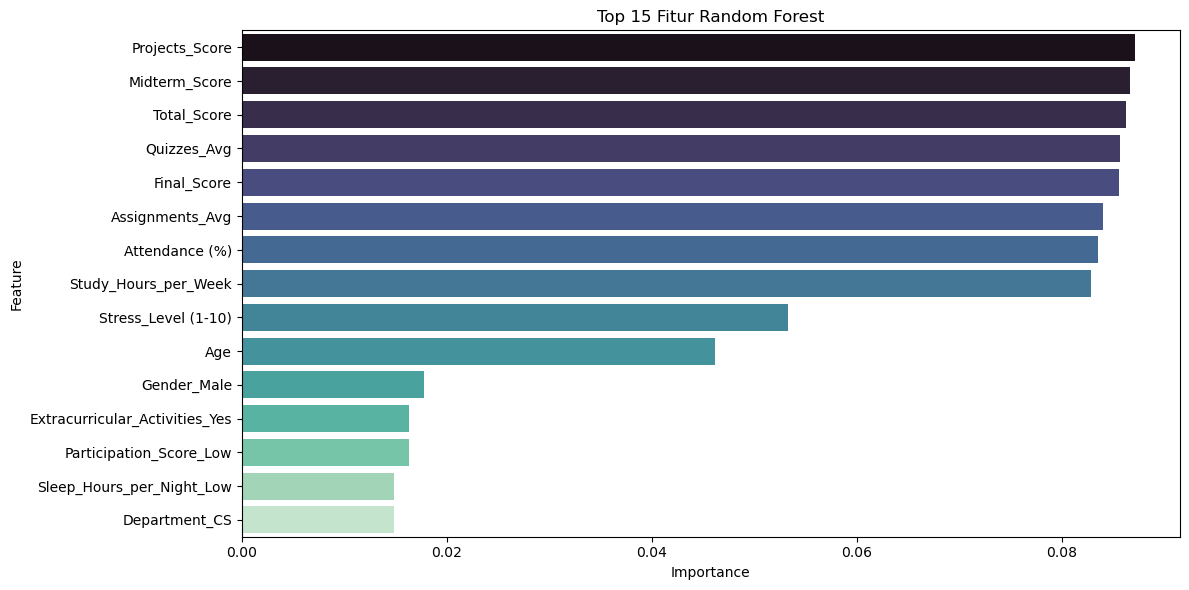


=== Classification Report (Test Set) ===
              precision    recall  f1-score   support

  Bachelor's       0.30      0.38      0.34       148
 High School       0.26      0.22      0.24       166
    Master's       0.23      0.20      0.21       158
         PhD       0.25      0.26      0.26       170

    accuracy                           0.26       642
   macro avg       0.26      0.27      0.26       642
weighted avg       0.26      0.26      0.26       642


Accuracy of Default Model: 0.2632


In [44]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

X = main_df.drop(columns=['Parent_Education_Level_encoded'])
y = main_df['Parent_Education_Level_encoded']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30]
}

random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=param_grid,
    n_iter=30,
    cv=5,
    n_jobs=-1,
    random_state=42
)

random_search.fit(X_train, y_train)
best_rf = random_search.best_estimator_
print("Best Params:", random_search.best_params_)

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
cv_scores = []

for train_index, val_index in skf.split(X, y):
    X_fold_train, X_fold_val = X.iloc[train_index], X.iloc[val_index]
    y_fold_train, y_fold_val = y.iloc[train_index], y.iloc[val_index]
    fold_model = clone(best_rf)
    fold_model.fit(X_fold_train, y_fold_train)
    score = fold_model.score(X_fold_val, y_fold_val)
    cv_scores.append(score)

print(f"Akurasi per fold: {np.round(cv_scores, 4)}")
print(f"Rata-rata akurasi: {np.mean(cv_scores):.4f}")
print(f"Standar deviasi  : {np.std(cv_scores):.4f}")

print()

# Feature Importance
importances = best_rf.feature_importances_
feat_imp_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(data=feat_imp_df.head(15), x='Importance', y='Feature', palette='mako')
plt.title('Top 15 Fitur Random Forest')
plt.tight_layout()
plt.show()

# Evaluasi
y_pred = best_rf.predict(X_test)

print("\n=== Classification Report (Test Set) ===")
print(classification_report(y_test, y_pred, target_names=le.classes_))

accuracy = accuracy_score(y_test, y_pred)
print(f"\nAccuracy of Default Model: {accuracy:.4f}")


## **Penerapan Model XGBoost**

Model kedua yang kami gunakan adalah XGBoost, dengan fungsi dan tujuan yang sama, yakni mengelompokkan kolom "parent_education_level" beserta fitur-fitur yang ada. Sama seperti Random Forest, kami encode kolomnya agar menjadi numerik, sehingga bisa diproses oleh modelnya yang hanya bisa mengolah angka saja. Kami juga menggunakan RandomizedSearchCV, dikarenakan hasilnya lebih baik dibandingkan dengan grid_search setelah kami uji. Kami juga menggunakan stratified kfold untuk menambah akurasi dari model ini. 


=== Evaluasi K-Fold Cross Validation ===
Akurasi tiap fold: [0.2399 0.2586 0.2461 0.2336 0.2555 0.2679 0.2156 0.1875 0.2375 0.2188]
Rata-rata akurasi: 0.2361
Standar deviasi  : 0.0226


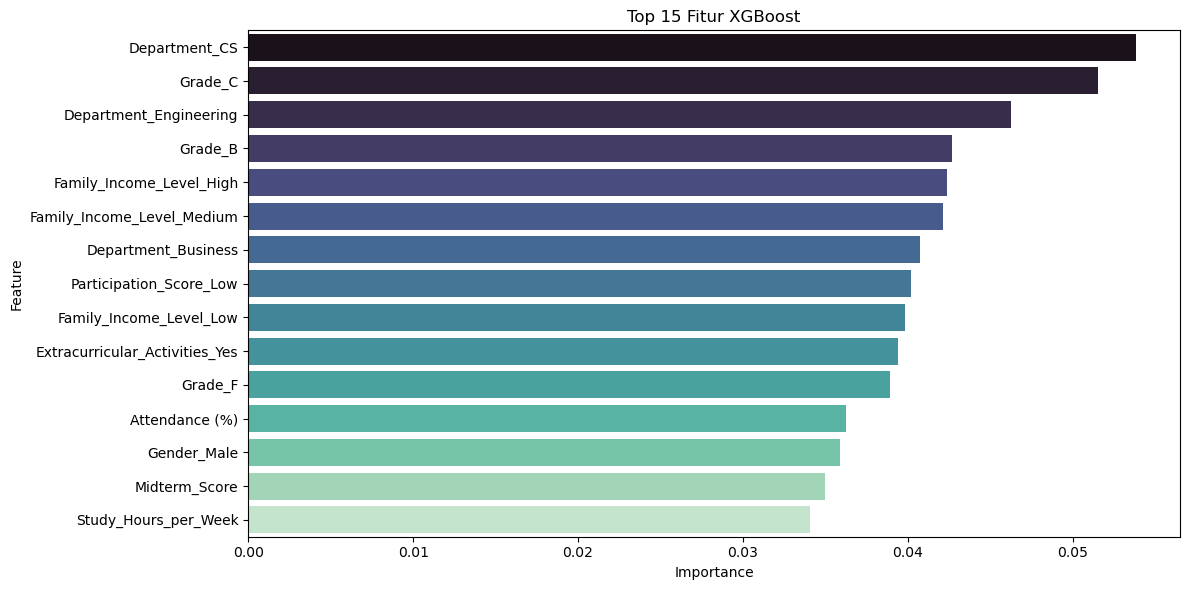


=== Classification Report (Test Set) ===
              precision    recall  f1-score   support

  Bachelor's       0.23      0.28      0.25       148
 High School       0.25      0.21      0.23       166
    Master's       0.21      0.18      0.19       158
         PhD       0.24      0.26      0.25       170

    accuracy                           0.23       642
   macro avg       0.23      0.23      0.23       642
weighted avg       0.23      0.23      0.23       642


Accuracy of Default Model: 0.2321


In [45]:
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

X = main_df.drop(columns=['Parent_Education_Level_encoded'])
y = main_df['Parent_Education_Level_encoded']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 6, 10],
    'learning_rate': [0.01, 0.1, 0.2]
}

xgb = XGBClassifier(random_state=42)
random_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_grid,
    n_iter=30,
    cv=5,
    n_jobs=-1,
    random_state=42
)

random_search.fit(X_train, y_train)
best_xgb = random_search.best_estimator_

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
cv_scores = []

for train_idx, val_idx in skf.split(X, y):
    X_fold_train, X_fold_val = X.iloc[train_idx], X.iloc[val_idx]
    y_fold_train, y_fold_val = y.iloc[train_idx], y.iloc[val_idx]
    fold_model = clone(best_xgb)
    fold_model.fit(X_fold_train, y_fold_train)
    score = fold_model.score(X_fold_val, y_fold_val)
    cv_scores.append(score)

print("\n=== Evaluasi K-Fold Cross Validation ===")
print(f"Akurasi tiap fold: {np.round(cv_scores, 4)}")
print(f"Rata-rata akurasi: {np.mean(cv_scores):.4f}")
print(f"Standar deviasi  : {np.std(cv_scores):.4f}")

importances = best_xgb.feature_importances_
feat_imp_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(data=feat_imp_df.head(15), x='Importance', y='Feature', palette='mako')
plt.title('Top 15 Fitur XGBoost')
plt.tight_layout()
plt.show()

# Evaluasi
y_pred = best_xgb.predict(X_test)

print("\n=== Classification Report (Test Set) ===")
print(classification_report(y_test, y_pred, target_names=le.classes_))

test_acc = accuracy_score(y_test, y_pred)
print(f"\nAccuracy of Default Model: {test_acc:.4f}")

## **Penerapan Naive Bayes**

Model terakhir yang kami gunakan sebagai perbandingan adalah Naive Bayes. Model ini sedikit berbeda dibandingkan dengan Random Forest dan XGBoost, dikarenakan Naive Bayes tidak dapat di tuning. Jadi, setelah melakukan train test split, kami langsung menggunakan stratified kfold tanpa dituning.

In [46]:
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

X = main_df.drop(columns=['Parent_Education_Level_encoded'])
y = main_df['Parent_Education_Level_encoded']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

gnb = GaussianNB()
gnb.fit(X_train, y_train)

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
cv_scores = []

for train_idx, val_idx in skf.split(X, y):
    X_fold_train, X_fold_val = X.iloc[train_idx], X.iloc[val_idx]
    y_fold_train, y_fold_val = y.iloc[train_idx], y.iloc[val_idx]
    gnb.fit(X_fold_train, y_fold_train)
    score = gnb.score(X_fold_val, y_fold_val)
    cv_scores.append(score)

print("\n=== Evaluasi K-Fold Cross Validation ===")
print(f"Akurasi tiap fold: {np.round(np.array(cv_scores)*100, 2)}%")
print(f"Rata-rata akurasi: {np.mean(cv_scores)*100:.2f}%")
print(f"Standar deviasi  : {np.std(cv_scores)*100:.2f}%")

# Evaluasi
gnb = GaussianNB()
gnb.fit(X_train, y_train)
y_pred = gnb.predict(X_test)

print("\n=== Classification Report (Test Set) ===")
print(classification_report(y_test, y_pred, target_names=le.classes_))

accuracy_default = accuracy_score(y_test, y_pred)
print(f"\nAccuracy of Default Model: {accuracy_default:.4f}")


=== Evaluasi K-Fold Cross Validation ===
Akurasi tiap fold: [25.86 23.36 28.66 21.81 21.81 24.3  22.19 19.69 24.38 24.38]%
Rata-rata akurasi: 23.64%
Standar deviasi  : 2.37%

=== Classification Report (Test Set) ===
              precision    recall  f1-score   support

  Bachelor's       0.26      0.21      0.23       148
 High School       0.26      0.34      0.30       166
    Master's       0.19      0.20      0.20       158
         PhD       0.27      0.22      0.24       170

    accuracy                           0.24       642
   macro avg       0.25      0.24      0.24       642
weighted avg       0.25      0.24      0.24       642


Accuracy of Default Model: 0.2445


## **Hasil Evaluasi antar model**

Hasil perbandingan antara model Random Forest, XGBoost, dan Naive Bayes menunjukkan bahwa ketiga model memiliki akurasi yang setara dengan tebakan acak. Dengan empat kelas yang seimbang, akurasi tebakan acak adalah sekitar 25%, dan rata-rata akurasi 10-fold stratified cross-validation berada di sekitar angka tersebut: Random Forest 25,76%, XGBoost 23,61%, dan Naive Bayes 23,64%. Akurasi pada test set juga sejalan, yaitu 26,32%, 23,21%, dan 24,45%.

**Catatan:** pada versi sebelumnya, Random Forest tampak memiliki akurasi test set sebesar 92,21%. Angka tersebut tidak valid karena terjadi *data leakage*: test set dievaluasi menggunakan model dari fold terakhir cross-validation, yang sudah dilatih dengan sekitar 90% baris test set. Setelah diperbaiki, test set hanya dievaluasi menggunakan model yang dilatih pada data training.

Random Forest tetap kami gunakan untuk mengisi parent_education_level yang kosong karena memiliki rata-rata akurasi cross-validation tertinggi, tetapi selisihnya terlalu kecil untuk dianggap bermakna. Artinya, fitur-fitur yang ada tidak mampu memprediksi parent_education_level, sehingga label hasil imputasi ini hampir setara dengan pelabelan acak.

## **Penggunaan Random Forest dalam klasifikasi Parent Education Level**

In [47]:
best_rf

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",30
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

In [48]:
X_target = nan_parent_edu_level_df.drop(['Parent_Education_Level'], axis=1)

In [49]:
RF_classify_labels = best_rf.predict(X_target)
nan_parent_edu_level_df['Parent_Education_Level_encoded'] = RF_classify_labels
nan_parent_edu_level_df.drop(['Parent_Education_Level'], axis=1, inplace=True)
nan_parent_edu_level_df.head()

,Age,Attendance (%),Midterm_Score,Final_Score,Assignments_Avg,Quizzes_Avg,Projects_Score,Total_Score,Study_Hours_per_Week,Stress_Level (1-10),...,Grade_D,Grade_F,Extracurricular_Activities_Yes,Internet_Access_at_Home_Yes,Family_Income_Level_High,Family_Income_Level_Low,Family_Income_Level_Medium,Participation_Score_Low,Sleep_Hours_per_Night_Low,Parent_Education_Level_encoded
1,-1.532177,0.945389,0.954151,0.096699,0.483508,0.885440,0.112823,0.012407,0.184346,0.333333,...,0,0,0,1,0,0,1,0,0,1
6,1.483524,0.151830,0.437813,0.818106,0.690676,0.968756,0.872975,0.664199,0.500491,0.444444,...,0,1,0,1,0,1,0,1,0,0
7,-1.029560,0.038008,0.094532,0.566189,0.602641,0.918686,0.864773,0.638583,1.325218,0.333333,...,0,1,1,0,0,0,1,1,1,1
9,0.478290,0.280056,0.799600,0.974825,0.939976,0.112157,0.571914,0.699820,-1.107726,1.000000,...,0,0,0,1,0,0,1,1,0,3
13,-1.532177,0.932186,0.010670,0.885962,0.335734,0.135990,0.629526,0.558535,0.706673,1.000000,...,0,0,0,1,0,0,1,1,0,1


In [50]:
main_df = pd.concat([main_df, nan_parent_edu_level_df], axis=0).reset_index(drop=True)
main_df.head()

,Age,Attendance (%),Midterm_Score,Final_Score,Assignments_Avg,Quizzes_Avg,Projects_Score,Total_Score,Study_Hours_per_Week,Stress_Level (1-10),...,Grade_D,Grade_F,Extracurricular_Activities_Yes,Internet_Access_at_Home_Yes,Family_Income_Level_High,Family_Income_Level_Low,Family_Income_Level_Medium,Participation_Score_Low,Sleep_Hours_per_Night_Low,Parent_Education_Level_encoded
0,0.478290,0.045609,0.250584,0.297099,0.684674,0.481274,0.717944,0.121473,-1.575071,0.444444,...,0,1,0,1,0,0,1,1,1,1
1,1.483524,0.143629,0.450984,0.894965,0.354142,0.714400,0.475695,0.405844,0.418018,0.555556,...,1,0,0,1,0,1,0,1,0,2
2,1.483524,0.902981,0.129877,0.677392,0.321329,0.870819,0.842368,0.232339,0.981582,0.222222,...,0,0,1,1,1,0,0,0,0,1
3,0.980907,0.083417,0.109870,0.648383,0.937375,0.674344,0.368274,0.322393,-0.310490,0.111111,...,0,1,1,1,1,0,0,1,0,1
4,-0.024327,0.508530,0.647716,0.058853,0.428171,0.043461,0.345669,0.241345,-1.258926,0.000000,...,0,0,1,1,1,0,0,0,1,3


In [51]:
main_df['Parent_Education_Level'] = le.inverse_transform(main_df['Parent_Education_Level_encoded'])
main_df.drop(['Parent_Education_Level_encoded'], axis=1, inplace=True)
main_df.head()

,Age,Attendance (%),Midterm_Score,Final_Score,Assignments_Avg,Quizzes_Avg,Projects_Score,Total_Score,Study_Hours_per_Week,Stress_Level (1-10),...,Grade_D,Grade_F,Extracurricular_Activities_Yes,Internet_Access_at_Home_Yes,Family_Income_Level_High,Family_Income_Level_Low,Family_Income_Level_Medium,Participation_Score_Low,Sleep_Hours_per_Night_Low,Parent_Education_Level
0,0.478290,0.045609,0.250584,0.297099,0.684674,0.481274,0.717944,0.121473,-1.575071,0.444444,...,0,1,0,1,0,0,1,1,1,High School
1,1.483524,0.143629,0.450984,0.894965,0.354142,0.714400,0.475695,0.405844,0.418018,0.555556,...,1,0,0,1,0,1,0,1,0,Master's
2,1.483524,0.902981,0.129877,0.677392,0.321329,0.870819,0.842368,0.232339,0.981582,0.222222,...,0,0,1,1,1,0,0,0,0,High School
3,0.980907,0.083417,0.109870,0.648383,0.937375,0.674344,0.368274,0.322393,-0.310490,0.111111,...,0,1,1,1,1,0,0,1,0,High School
4,-0.024327,0.508530,0.647716,0.058853,0.428171,0.043461,0.345669,0.241345,-1.258926,0.000000,...,0,0,1,1,1,0,0,0,1,PhD


In [52]:
# To one hot encode the parent_education_level
encoder = OneHotEncoder(sparse_output=False, dtype='int64', drop='if_binary')

categorical_cols = ['Parent_Education_Level']

encoded_arr = encoder.fit_transform(main_df[categorical_cols])

encoded_df = pd.DataFrame(encoded_arr, columns=encoder.get_feature_names_out(categorical_cols))

main_df = pd.concat([main_df.drop(columns=categorical_cols), encoded_df], axis=1)

main_df.head()

,Age,Attendance (%),Midterm_Score,Final_Score,Assignments_Avg,Quizzes_Avg,Projects_Score,Total_Score,Study_Hours_per_Week,Stress_Level (1-10),...,Internet_Access_at_Home_Yes,Family_Income_Level_High,Family_Income_Level_Low,Family_Income_Level_Medium,Participation_Score_Low,Sleep_Hours_per_Night_Low,Parent_Education_Level_Bachelor's,Parent_Education_Level_High School,Parent_Education_Level_Master's,Parent_Education_Level_PhD
0,0.478290,0.045609,0.250584,0.297099,0.684674,0.481274,0.717944,0.121473,-1.575071,0.444444,...,1,0,0,1,1,1,0,1,0,0
1,1.483524,0.143629,0.450984,0.894965,0.354142,0.714400,0.475695,0.405844,0.418018,0.555556,...,1,0,1,0,1,0,0,0,1,0
2,1.483524,0.902981,0.129877,0.677392,0.321329,0.870819,0.842368,0.232339,0.981582,0.222222,...,1,1,0,0,0,0,0,1,0,0
3,0.980907,0.083417,0.109870,0.648383,0.937375,0.674344,0.368274,0.322393,-0.310490,0.111111,...,1,1,0,0,1,0,0,1,0,0
4,-0.024327,0.508530,0.647716,0.058853,0.428171,0.043461,0.345669,0.241345,-1.258926,0.000000,...,1,1,0,0,0,1,0,0,0,1


# *Tugas 2 - Prediksi*
Catatan: Sertakan juga pengukuran kinerja dan evaluasi antar model dan visualisasikan!

Tujuan utama: "Prediksi nilai akhir siswa dan Prediksi tingkat stress siswa"

In [53]:
main_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 31 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Age                                 5000 non-null   float64
 1   Attendance (%)                      5000 non-null   float64
 2   Midterm_Score                       5000 non-null   float64
 3   Final_Score                         5000 non-null   float64
 4   Assignments_Avg                     5000 non-null   float64
 5   Quizzes_Avg                         5000 non-null   float64
 6   Projects_Score                      5000 non-null   float64
 7   Total_Score                         5000 non-null   float64
 8   Study_Hours_per_Week                5000 non-null   float64
 9   Stress_Level (1-10)                 5000 non-null   float64
 10  Gender_Male                         5000 non-null   int64  
 11  Department_Business                 5000 no

## **Penerapan Model Linear Regression**

In [54]:
numeric_df = main_df.select_dtypes(include='number')

In [55]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

def evaluation(y_true, y_pred,data=""):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print(f"--- Evaluasi {data} ---")
    print(f"MAE : {mae:.4f}")
    print(f"MSE : {mse:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R²  : {r2:.4f}")
    return mae, mse, rmse, r2


In [56]:
def plot_Actual_vs_Predicted(Y_test, Y_pred,data=""):
      plt.figure(figsize=(8,6))
      plt.scatter(Y_test, Y_pred, color='blue', edgecolors='black', alpha=0.6)
      plt.xlabel('Nilai Asli')
      plt.ylabel('Nilai Prediksi')
      plt.title(f'Nilai Asli Vs Nilai Prediksi {data}')
      plt.grid(True)
      plt.tight_layout()
      plt.show()

def plot_residuals(y_test, y_pred,data=""):
    residuals = y_test - y_pred

    plt.figure(figsize=(8, 5))
    plt.scatter(y_pred, residuals, alpha=0.6, edgecolor='black')
    plt.xlabel("Nilai yang Diprediksi")
    plt.ylabel("Sisa")
    plt.title(f"Plot Sisa {data}")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

def plot_residual_histogram(y_true, y_pred,data="", bins=30):
    residuals = y_true - y_pred

    plt.figure(figsize=(8, 5))
    plt.hist(residuals, bins=bins, edgecolor='black', alpha=0.7)
    plt.xlabel("Sisa")
    plt.ylabel("Frekuensi")
    plt.title(f"Histogram Sisa {data}")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [57]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

def evaluate_linear_regression(numeric_df, target_column, test_size, random_state, plot=True):
    Y = numeric_df[target_column].values
    X = numeric_df.drop(columns=[target_column]).values

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    X_train, X_test, Y_train, Y_test = train_test_split(X_scaled, Y, test_size=test_size, random_state=random_state)

    regressor = LinearRegression()
    regressor.fit(X_train, Y_train)

    Y_pred = regressor.predict(X_test)

    evaluation(Y_test, Y_pred,target_column)

    if plot:
        plot_Actual_vs_Predicted(Y_test, Y_pred,target_column)
        plot_residuals(Y_test,Y_pred,target_column)
        plot_residual_histogram(Y_test,Y_pred,target_column)

--- Evaluasi Total_Score ---
MAE : 0.2463
MSE : 0.0820
RMSE: 0.2864
R²  : -0.0155


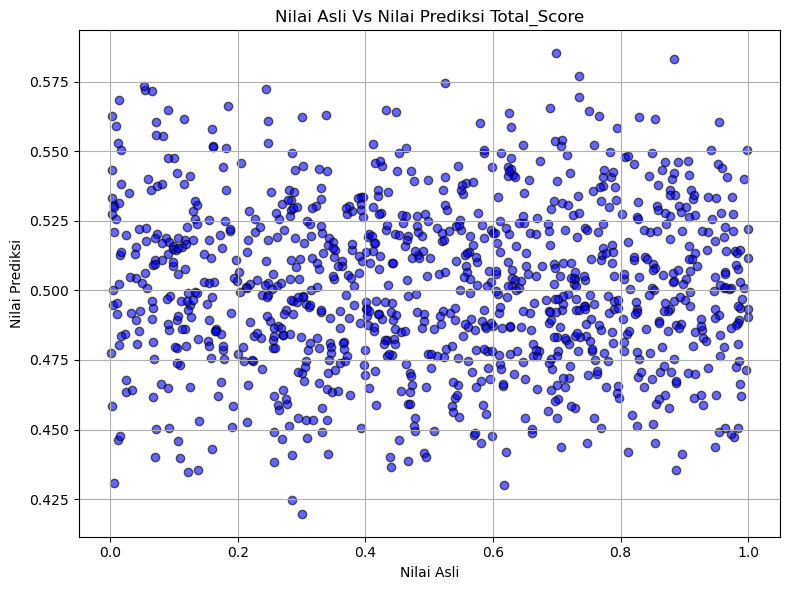

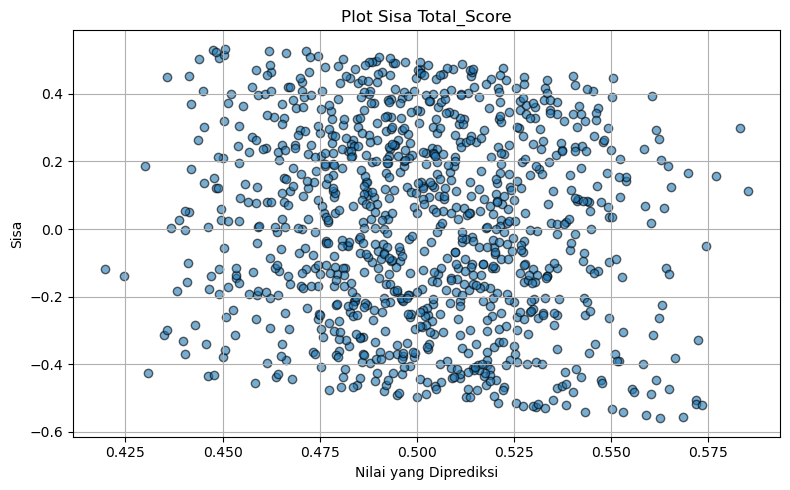

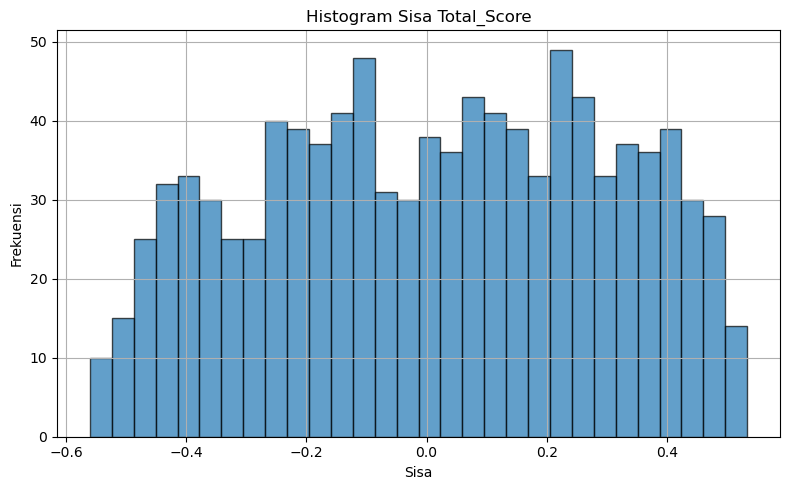

In [58]:
evaluate_linear_regression(numeric_df,'Total_Score',0.2,0,True)

Dari grafik yang ditampilkan di atas, dapat dilihat bahwa model ini masih menghasilkan jumlah error yang signifikan. Error tersebut tersebar merata di seluruh prediksi, yang menunjukkan bahwa model belum sepenuhnya dapat menggeneralisasi dengan baik terhadap data yang ada.

--- Evaluasi Stress_Level (1-10) ---
MAE : 0.2693
MSE : 0.0980
RMSE: 0.3131
R²  : -0.0023


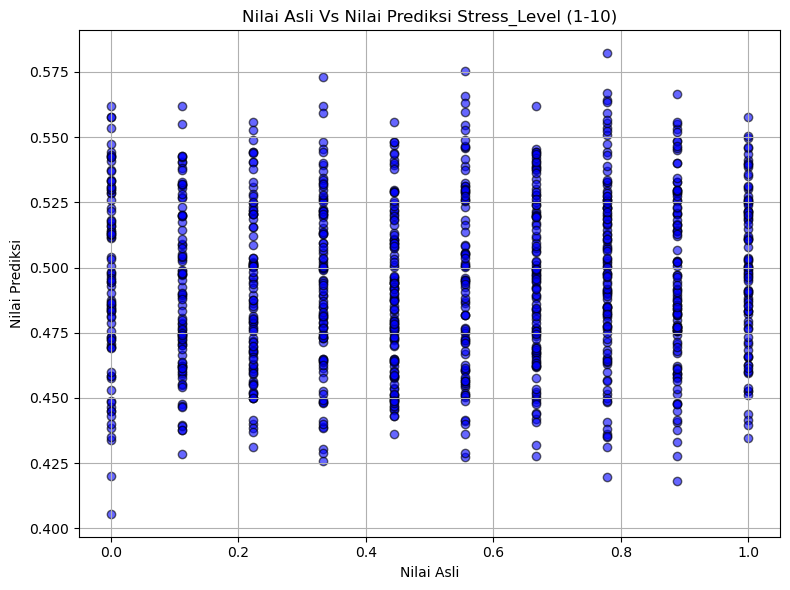

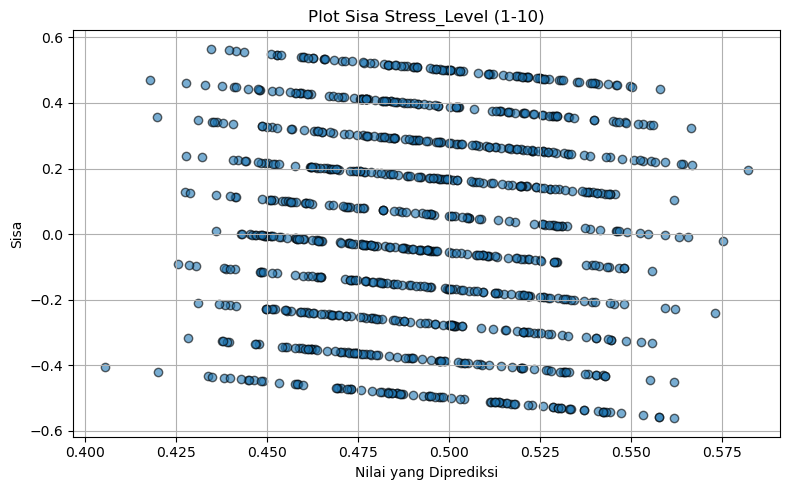

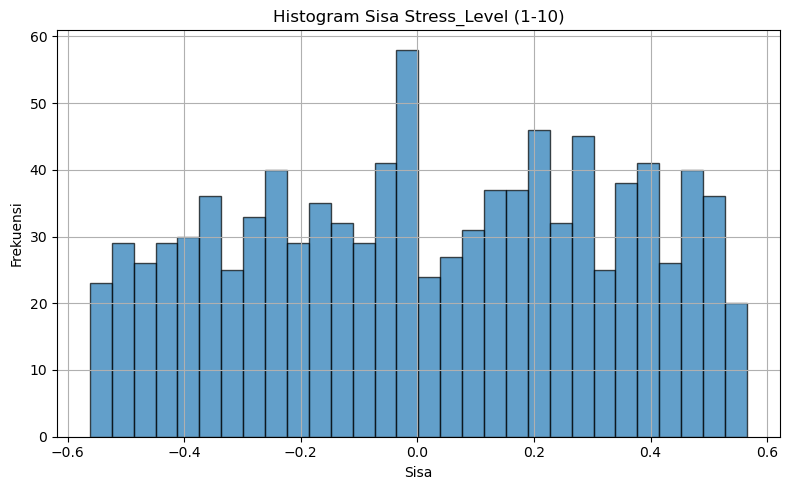

In [59]:
evaluate_linear_regression(numeric_df,'Stress_Level (1-10)',0.2,0,True)

Dari grafik yang ditampilkan di atas, dapat dilihat bahwa model ini masih menghasilkan jumlah error yang signifikan. Error tersebut tersebar merata di seluruh prediksi, yang menunjukkan bahwa model belum sepenuhnya dapat menggeneralisasi dengan baik terhadap data yang ada.

## **Penerapan Model Polynomial Regression**

In [60]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

def evaluate_polynomial_regression(numeric_df, target_column, max_degree, test_size=0.2, random_state=0):
    Y = numeric_df[target_column].values
    X = numeric_df.drop(columns=[target_column]).values

    X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=test_size, random_state=random_state)

    for degree in range(1, max_degree + 1):
        poly = PolynomialFeatures(degree=degree)
        X_train_poly = poly.fit_transform(X_train)
        X_test_poly = poly.transform(X_test)

        regressor = LinearRegression()
        regressor.fit(X_train_poly, y_train)

        y_pred = regressor.predict(X_test_poly)

        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        print(f"RMSE (degree {degree}): {rmse:.4f}")


In [61]:
def compare_polynomial_degrees(numeric_df, target_column='Total_Score', degrees = [1], test_size=0.2, random_state=0, plot=True):
    Y = numeric_df[target_column].values
    X = numeric_df.drop(columns=[target_column]).values

    X_train, X_test, y_train, Y_test = train_test_split(X, Y, test_size=test_size, random_state=random_state)

    for i in range(len(degrees)):
        poly = PolynomialFeatures(degree=degrees[i])
        X_train_poly = poly.fit_transform(X_train)
        X_test_poly = poly.transform(X_test)

        model = LinearRegression()
        model.fit(X_train_poly, y_train)
        Y_pred = model.predict(X_test_poly)

        print(f"Evaluasi derajat {degrees[i]}")
        evaluation(Y_test, Y_pred, target_column)

        if plot:
            plot_Actual_vs_Predicted(Y_test, Y_pred,target_column)
            plot_residuals(Y_test,Y_pred,target_column)
            plot_residual_histogram(Y_test,Y_pred,target_column)


In [62]:
evaluate_polynomial_regression(numeric_df,'Total_Score',4,0.2,0)

RMSE (degree 1): 0.2864
RMSE (degree 2): 0.2966
RMSE (degree 3): 0.5983
RMSE (degree 4): 0.5120


Evaluasi derajat 1
--- Evaluasi Total_Score ---
MAE : 0.2463
MSE : 0.0820
RMSE: 0.2864
R²  : -0.0155


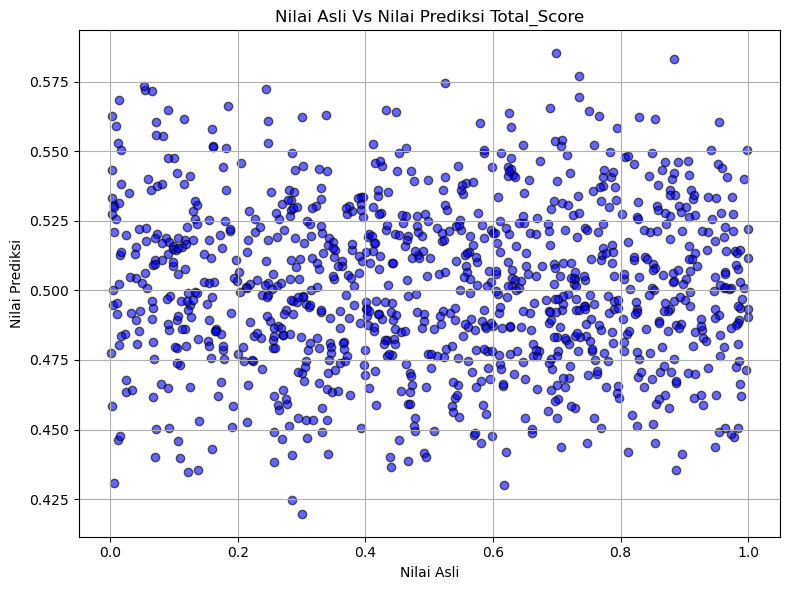

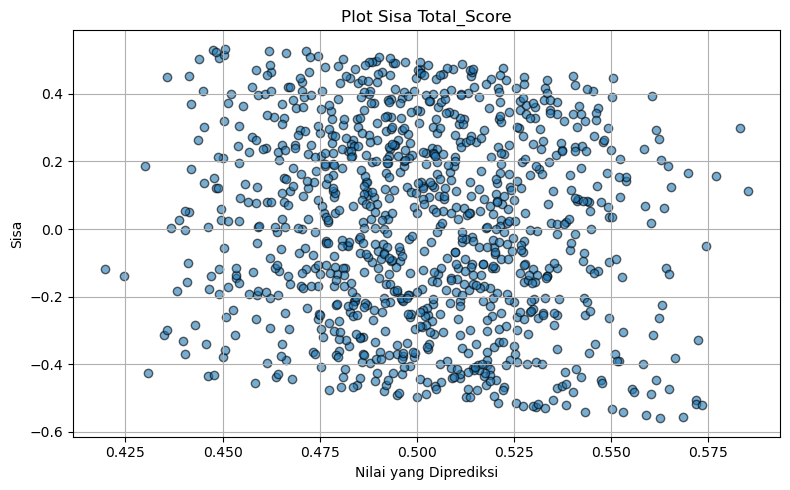

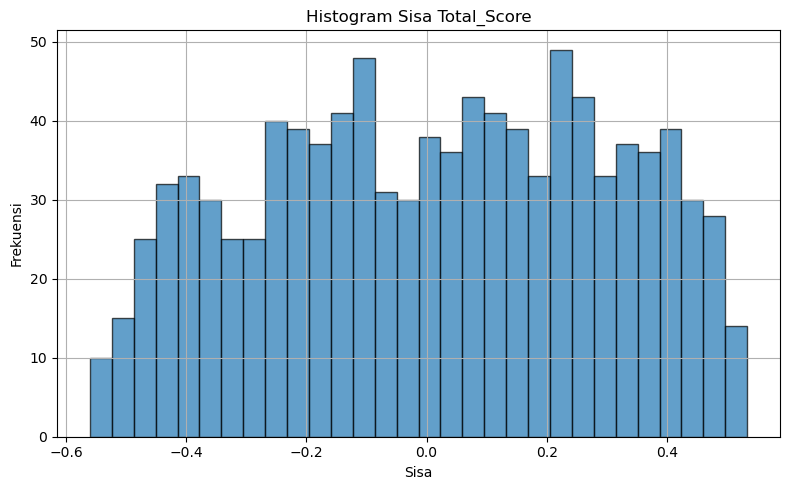

Evaluasi derajat 2
--- Evaluasi Total_Score ---
MAE : 0.2497
MSE : 0.0879
RMSE: 0.2966
R²  : -0.0892


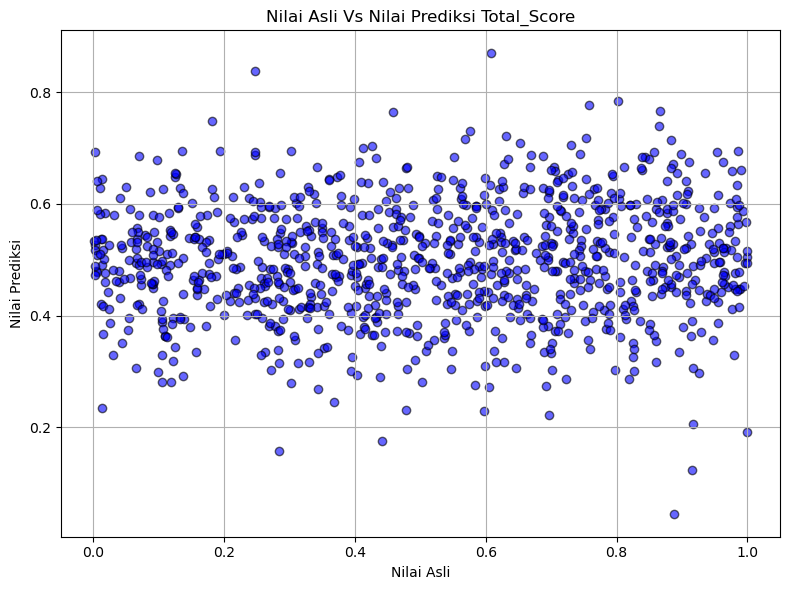

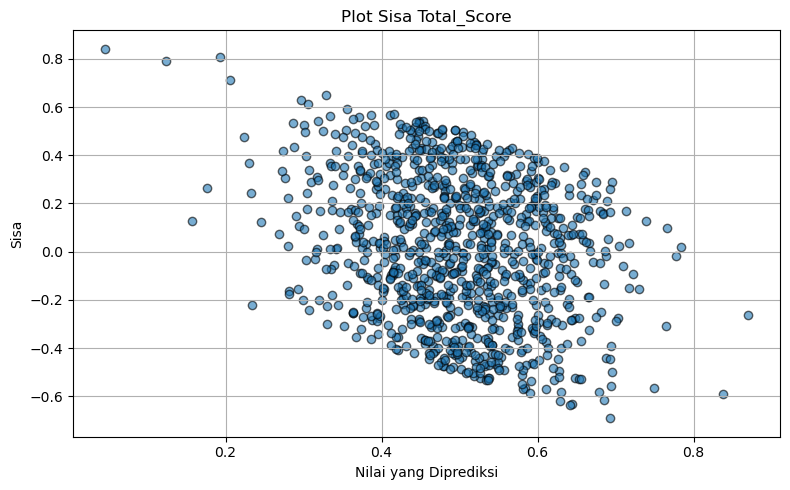

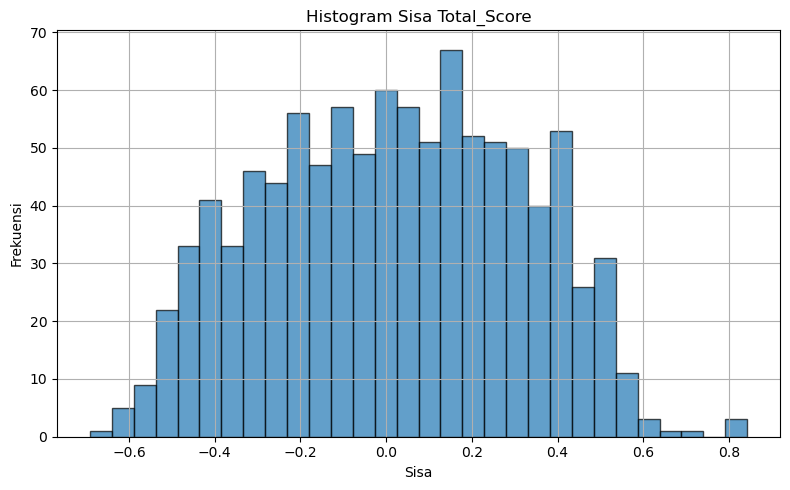

In [63]:
compare_polynomial_degrees(numeric_df,'Total_Score',[1,2])

Dari grafik yang ditampilkan di atas, dapat dilihat bahwa model ini masih menghasilkan jumlah error yang signifikan. Error tersebut tersebar merata di seluruh prediksi, yang menunjukkan bahwa model belum sepenuhnya dapat menggeneralisasi dengan baik terhadap data yang ada.

In [64]:
evaluate_polynomial_regression(numeric_df,'Stress_Level (1-10)',4,0.2,0)

RMSE (degree 1): 0.3131
RMSE (degree 2): 0.3205
RMSE (degree 3): 0.7399
RMSE (degree 4): 0.5579


Evaluasi derajat 1
--- Evaluasi Stress_Level (1-10) ---
MAE : 0.2693
MSE : 0.0980
RMSE: 0.3131
R²  : -0.0023


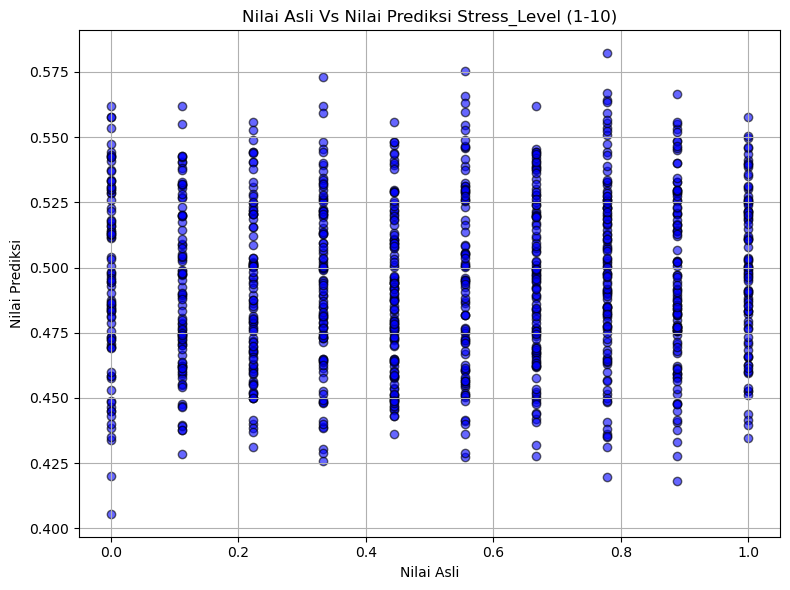

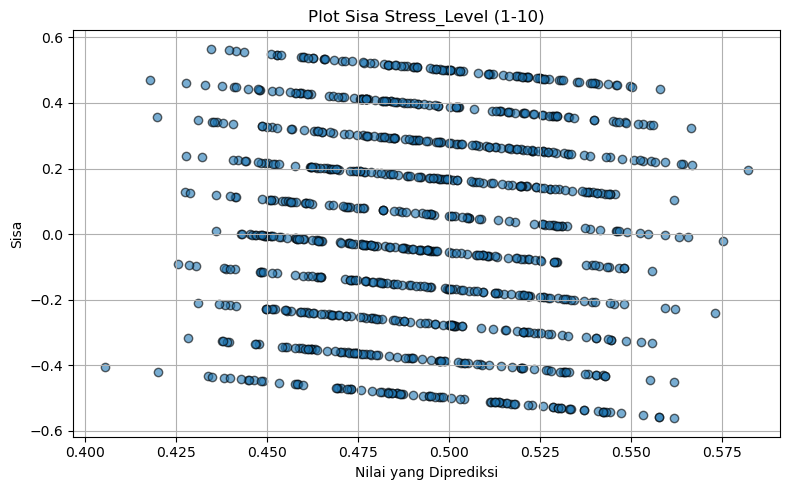

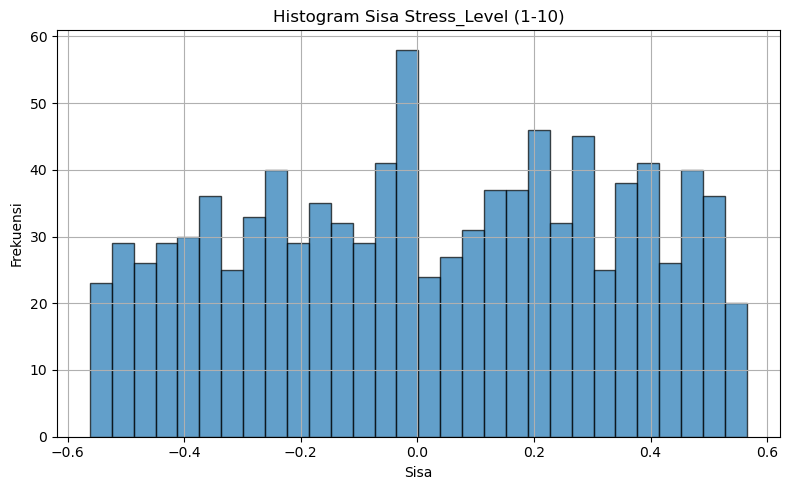

Evaluasi derajat 2
--- Evaluasi Stress_Level (1-10) ---
MAE : 0.2730
MSE : 0.1027
RMSE: 0.3205
R²  : -0.0504


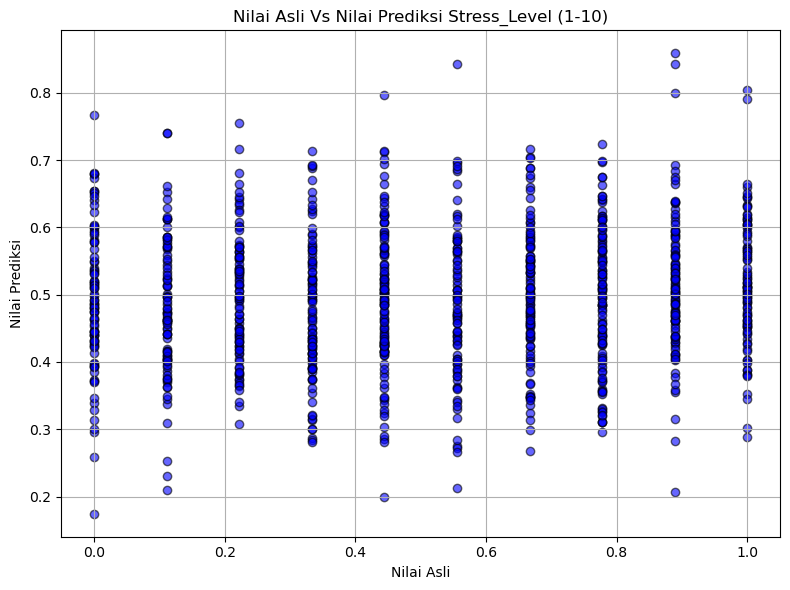

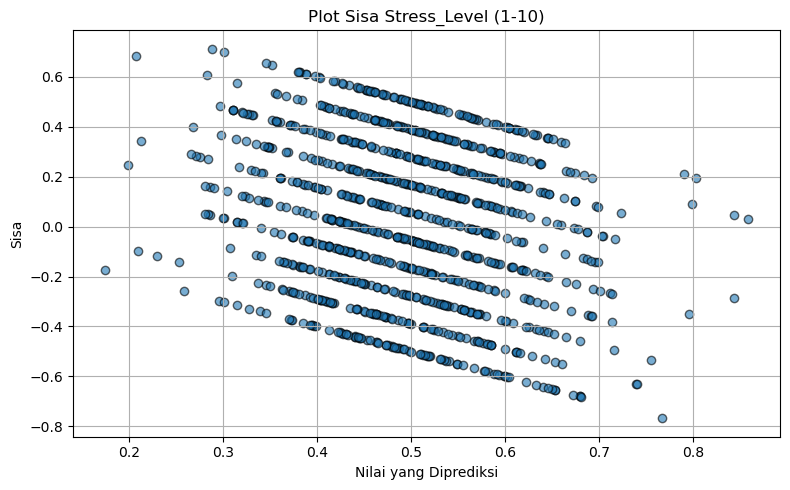

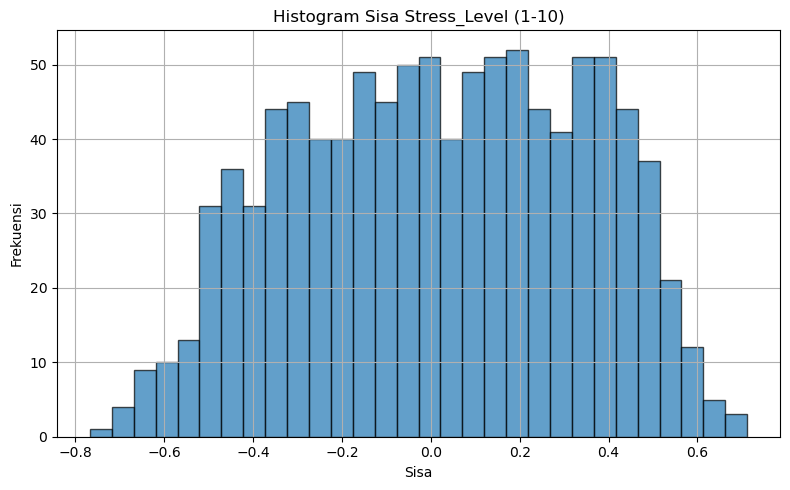

In [65]:
compare_polynomial_degrees(numeric_df,'Stress_Level (1-10)',[1,2])

Dari grafik yang ditampilkan di atas, dapat dilihat bahwa model ini masih menghasilkan jumlah error yang signifikan. Error tersebut tersebar merata di seluruh prediksi, yang menunjukkan bahwa model belum sepenuhnya dapat menggeneralisasi dengan baik terhadap data yang ada.

## **Penerapan Model Random Forest Regressor**

In [66]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

def Random_Forest_Regressor(numeric_df, target_column, estimators_list=[100], plot=True):
    Y = numeric_df[target_column].values
    X = numeric_df.drop(columns=[target_column]).values

    X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

    for num_estimators in estimators_list:
        model = RandomForestRegressor(n_estimators=num_estimators, random_state=42)
        model.fit(X_train, Y_train)

        Y_pred = model.predict(X_test)

        print(f"evaluasi estimator {num_estimators}")
        evaluation(Y_test, Y_pred,target_column)

        if plot:
            plot_Actual_vs_Predicted(Y_test, Y_pred,target_column)
            plot_residuals(Y_test,Y_pred,target_column)
            plot_residual_histogram(Y_test,Y_pred,target_column)


evaluasi estimator 100
--- Evaluasi Total_Score ---
MAE : 0.2568
MSE : 0.0880
RMSE: 0.2966
R²  : -0.0348


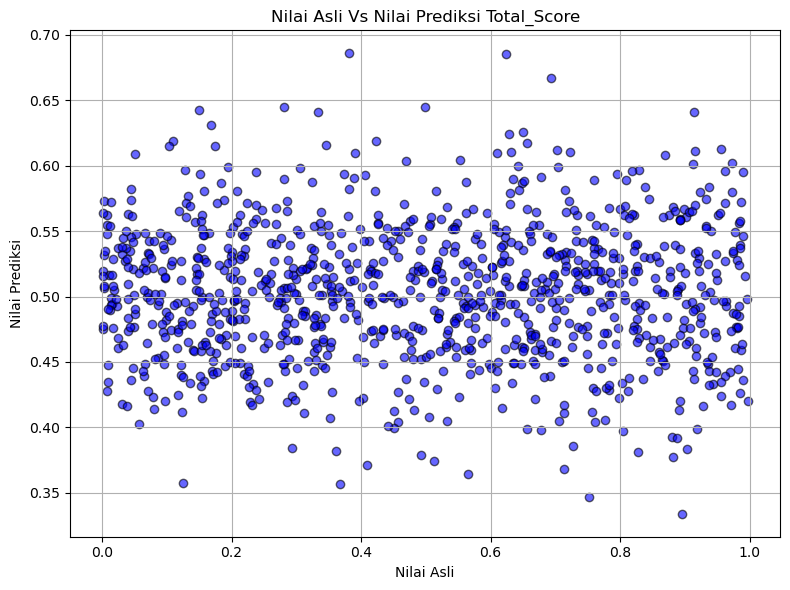

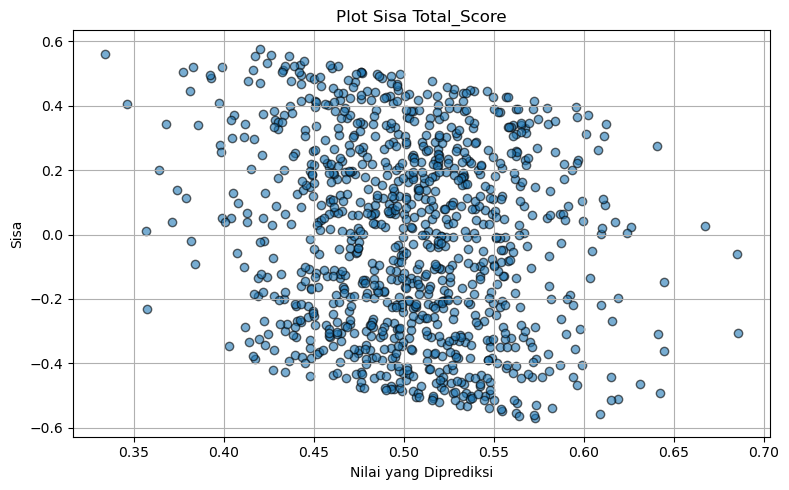

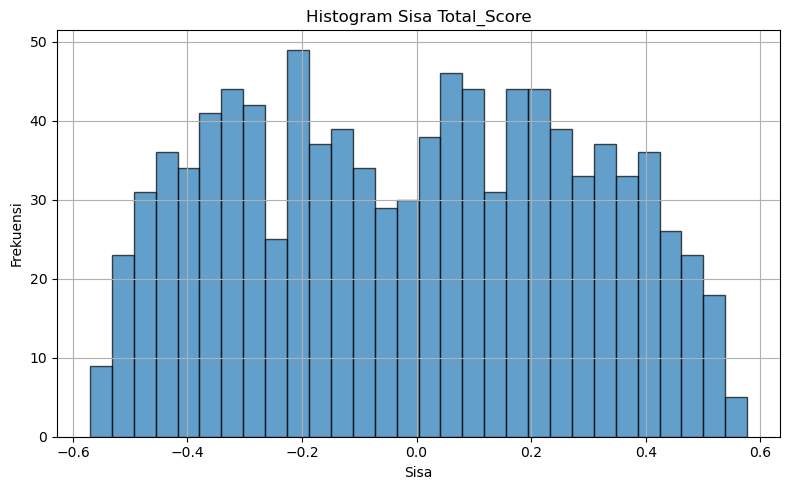

evaluasi estimator 200
--- Evaluasi Total_Score ---
MAE : 0.2566
MSE : 0.0878
RMSE: 0.2963
R²  : -0.0326


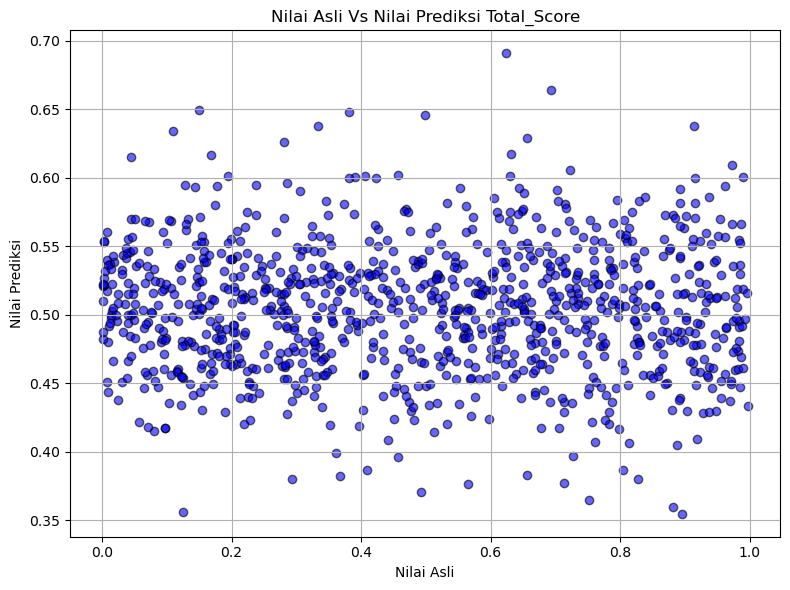

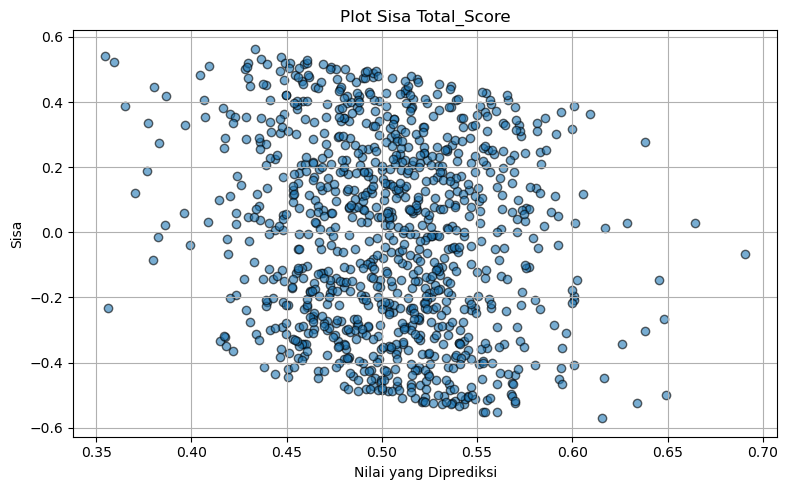

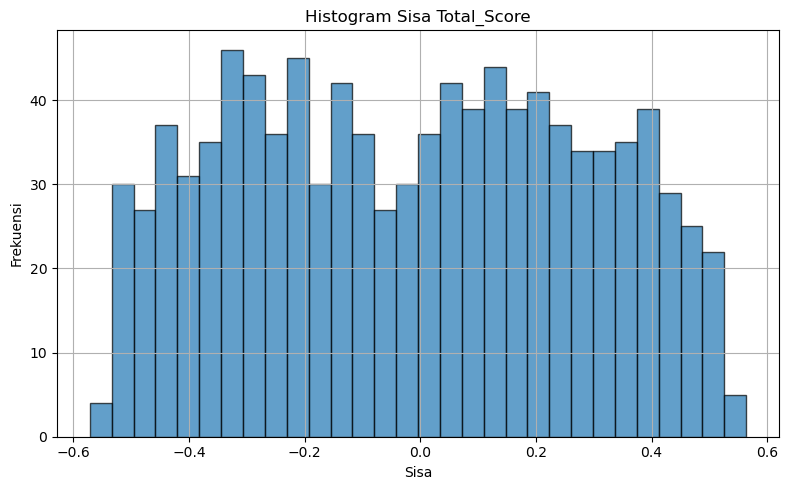

evaluasi estimator 300
--- Evaluasi Total_Score ---
MAE : 0.2566
MSE : 0.0877
RMSE: 0.2961
R²  : -0.0315


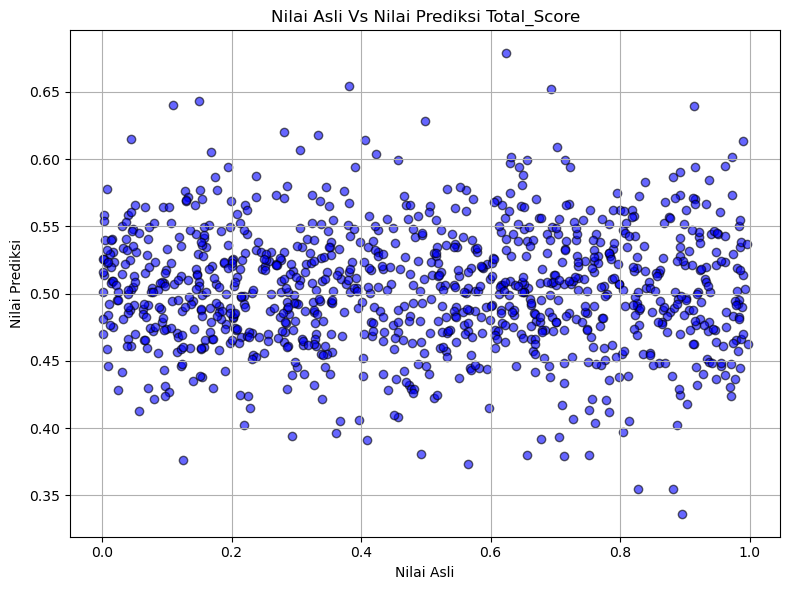

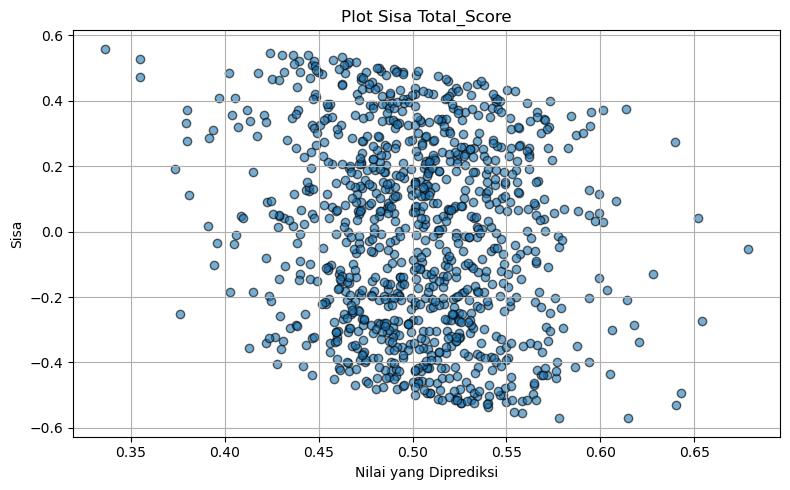

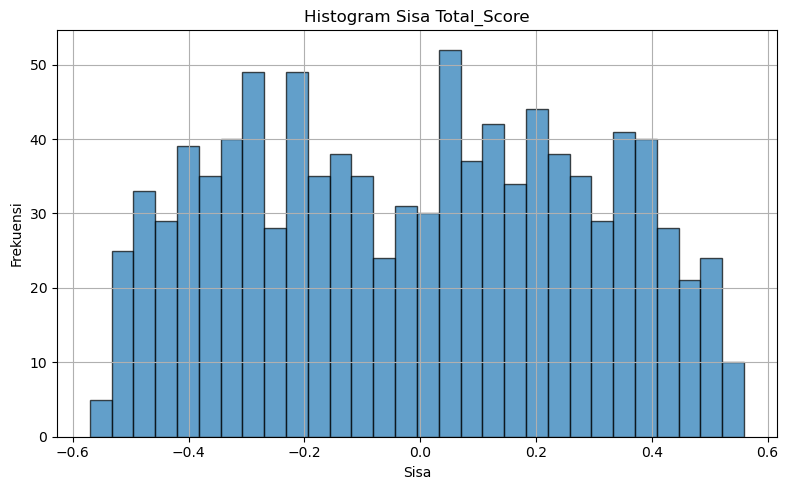

evaluasi estimator 400
--- Evaluasi Total_Score ---
MAE : 0.2565
MSE : 0.0875
RMSE: 0.2957
R²  : -0.0287


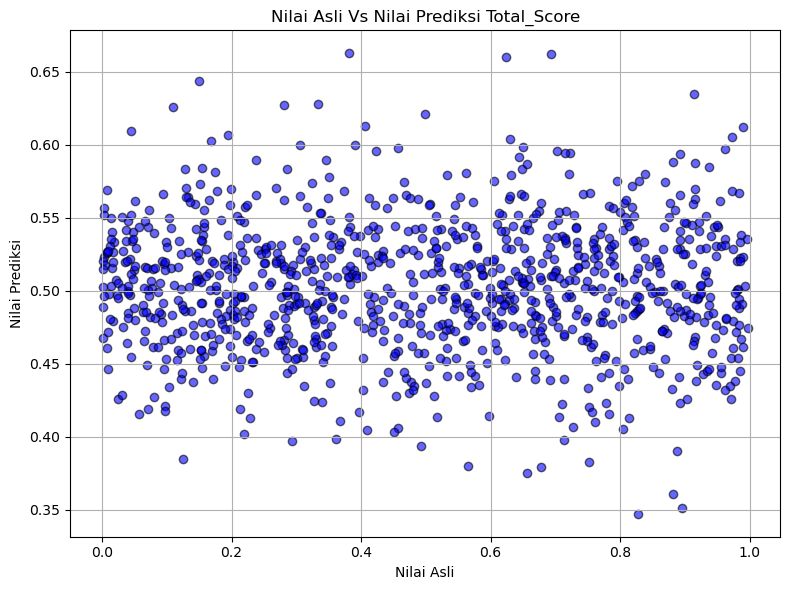

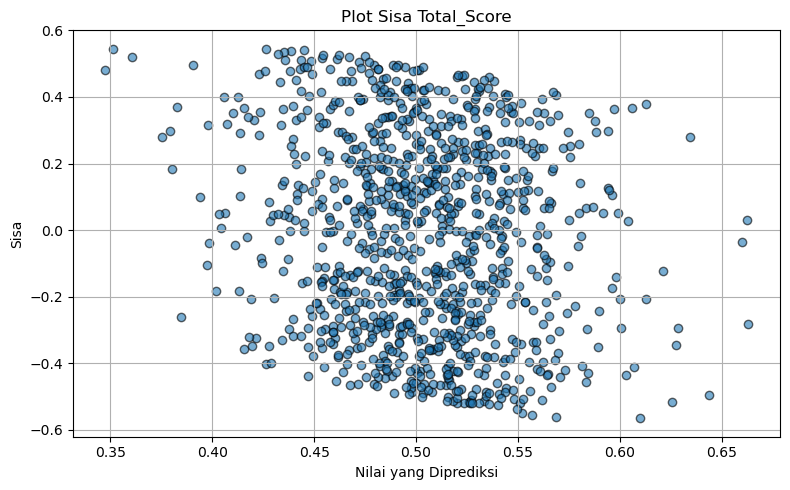

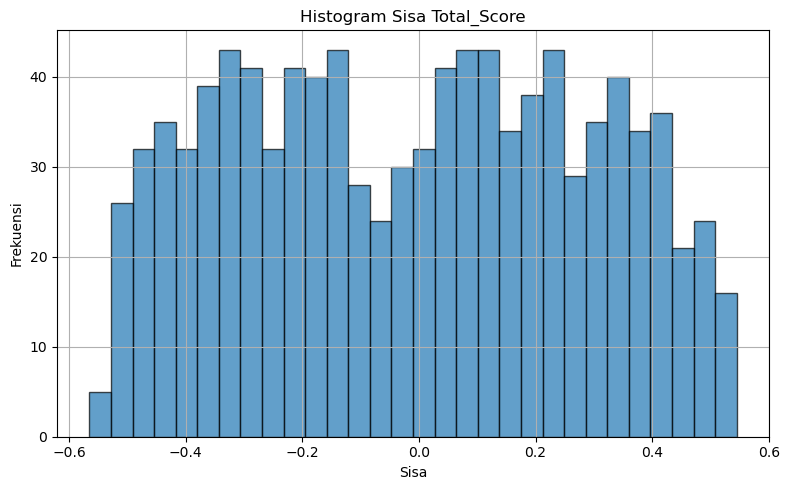

In [67]:
Random_Forest_Regressor(numeric_df,'Total_Score',[100,200,300,400])

Dari grafik yang ditampilkan di atas, dapat dilihat bahwa model ini masih menghasilkan jumlah error yang signifikan. Error tersebut tersebar merata di seluruh prediksi, yang menunjukkan bahwa model belum sepenuhnya dapat menggeneralisasi dengan baik terhadap data yang ada.

evaluasi estimator 100
--- Evaluasi Stress_Level (1-10) ---
MAE : 0.2797
MSE : 0.1042
RMSE: 0.3228
R²  : -0.0168


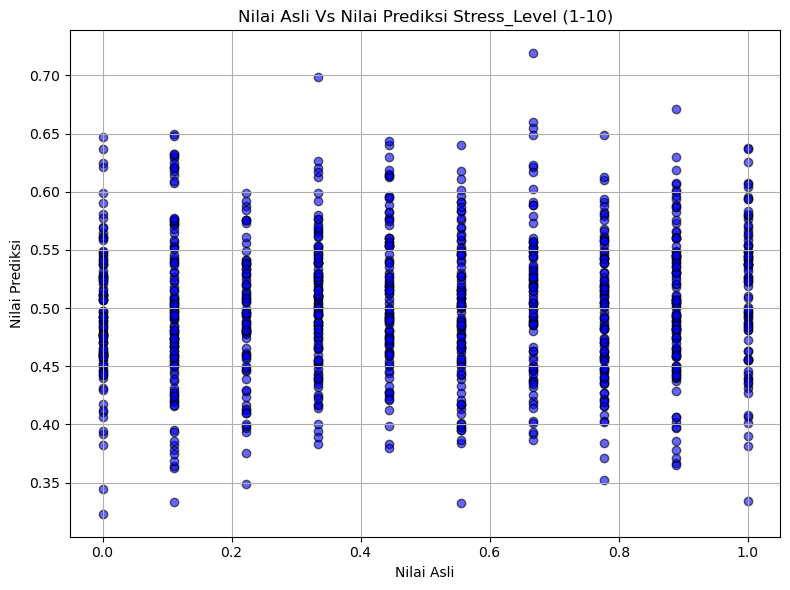

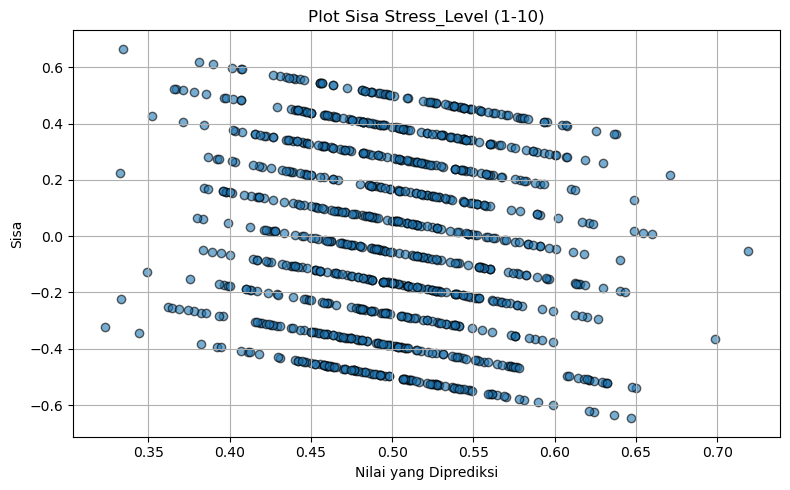

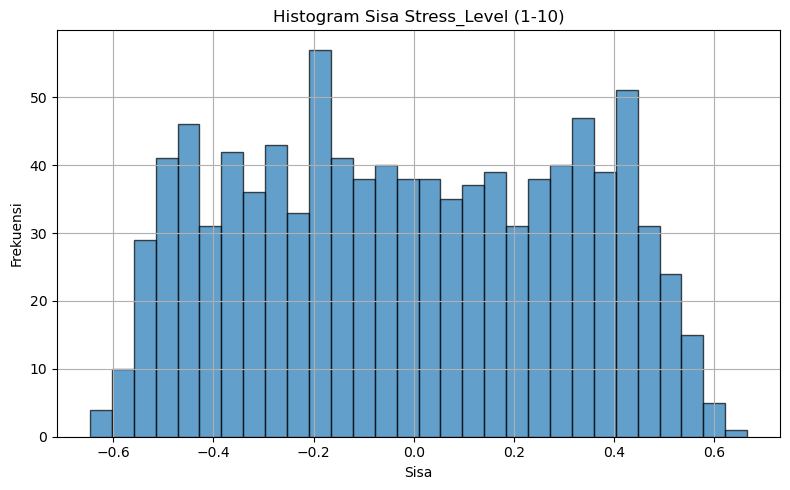

evaluasi estimator 200
--- Evaluasi Stress_Level (1-10) ---
MAE : 0.2790
MSE : 0.1038
RMSE: 0.3221
R²  : -0.0123


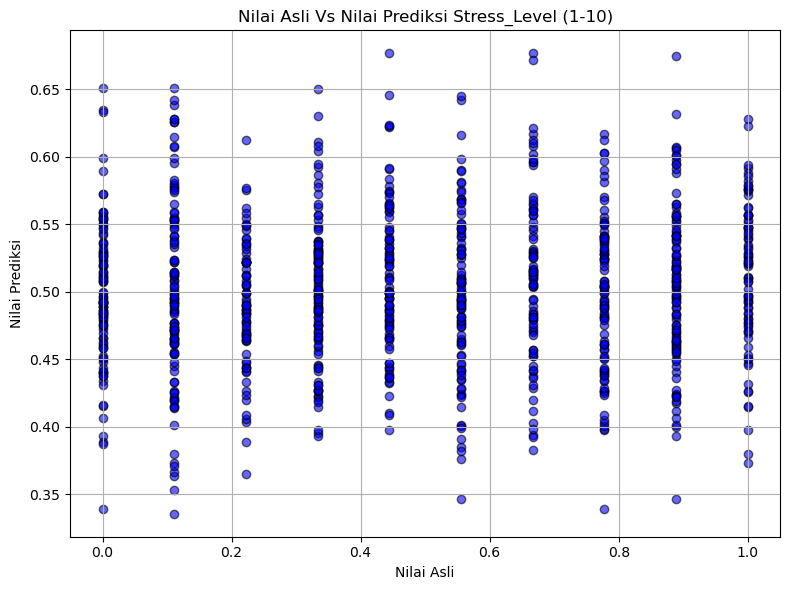

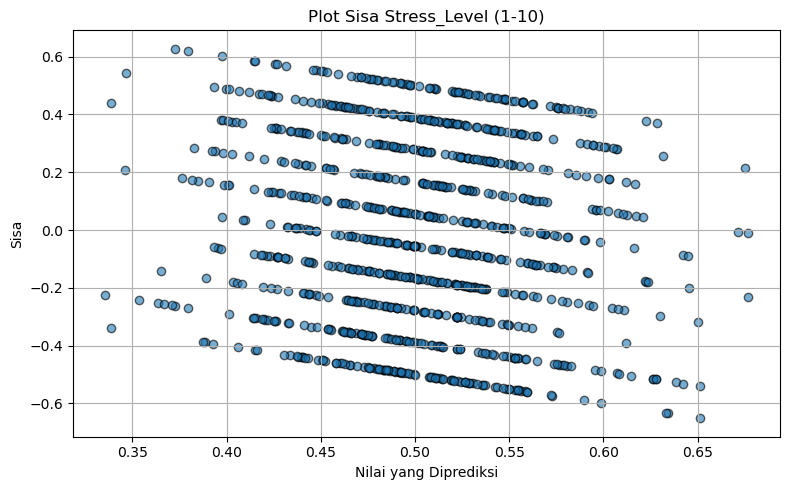

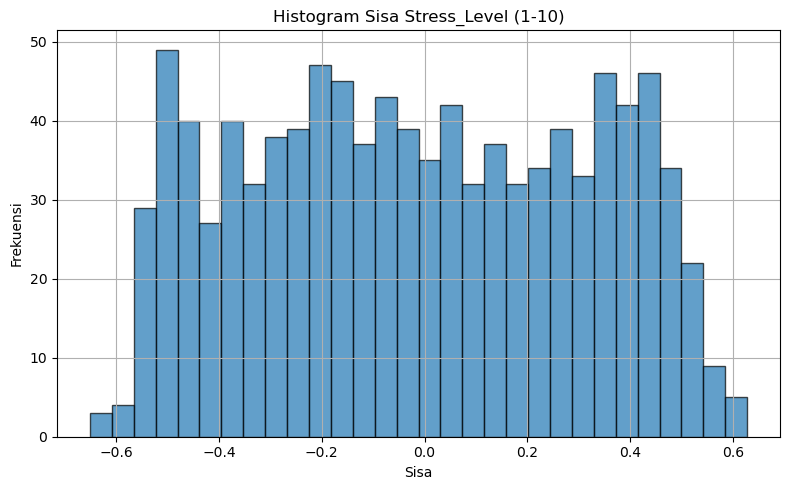

evaluasi estimator 300
--- Evaluasi Stress_Level (1-10) ---
MAE : 0.2793
MSE : 0.1039
RMSE: 0.3224
R²  : -0.0141


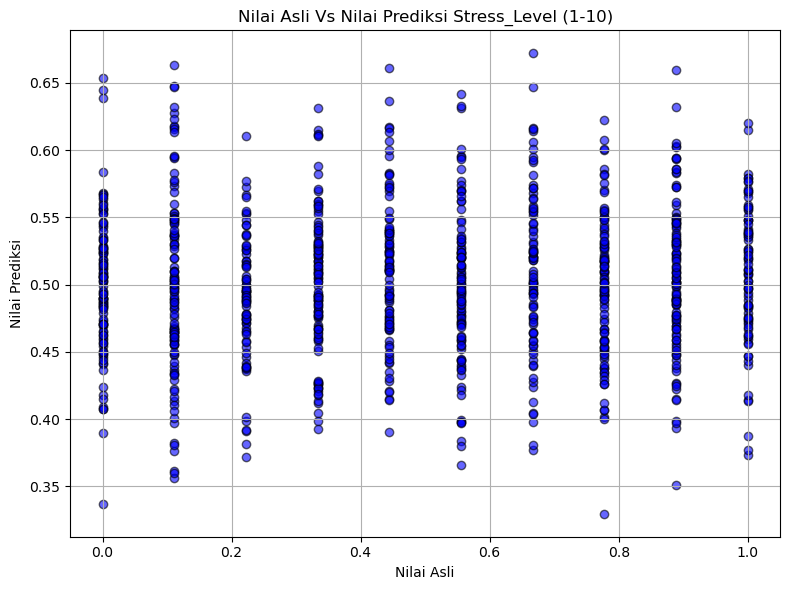

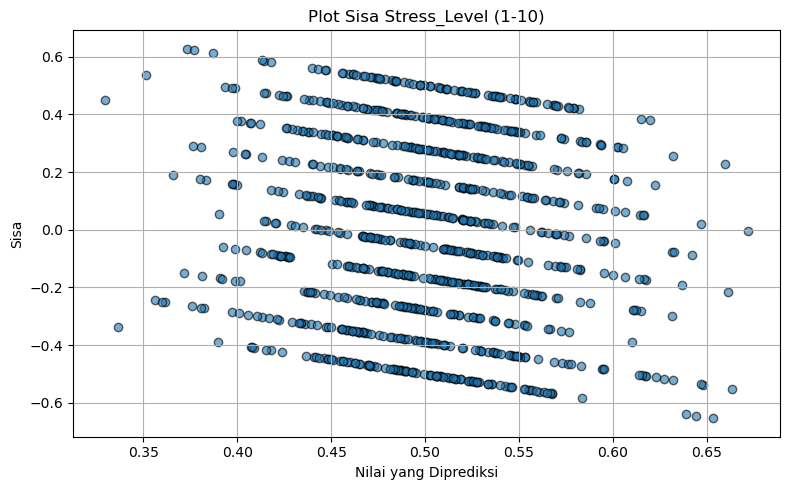

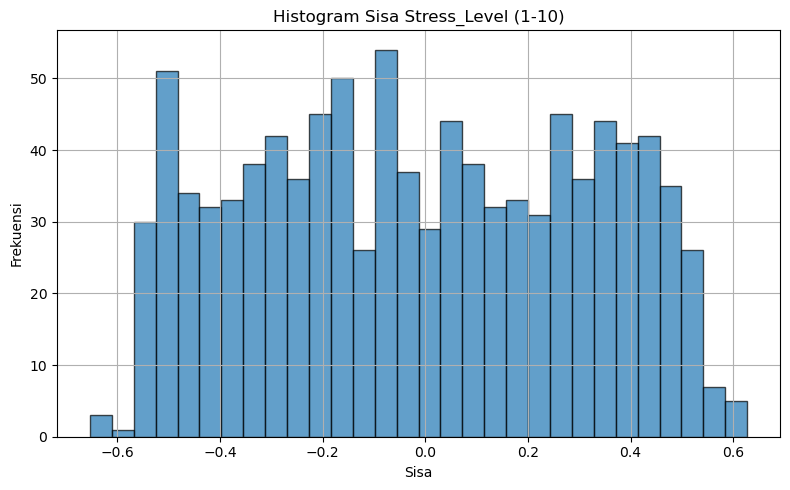

evaluasi estimator 400
--- Evaluasi Stress_Level (1-10) ---
MAE : 0.2792
MSE : 0.1037
RMSE: 0.3220
R²  : -0.0114


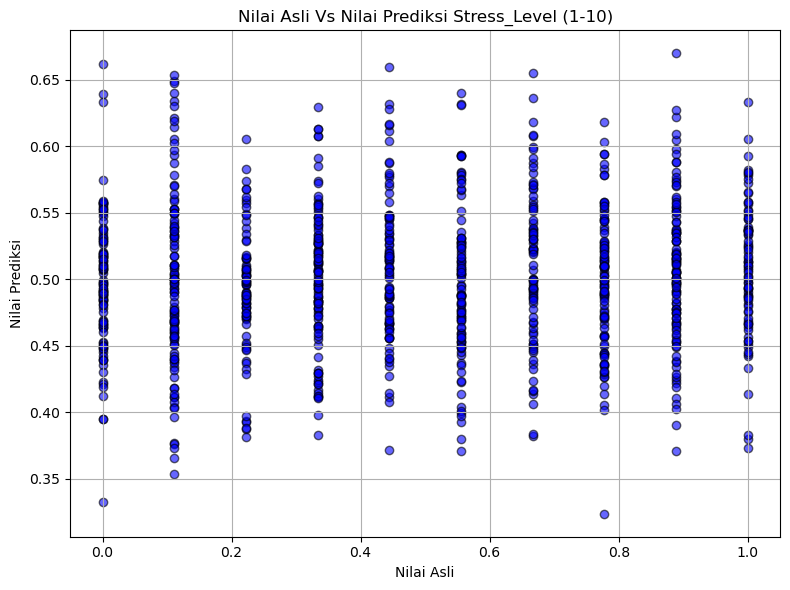

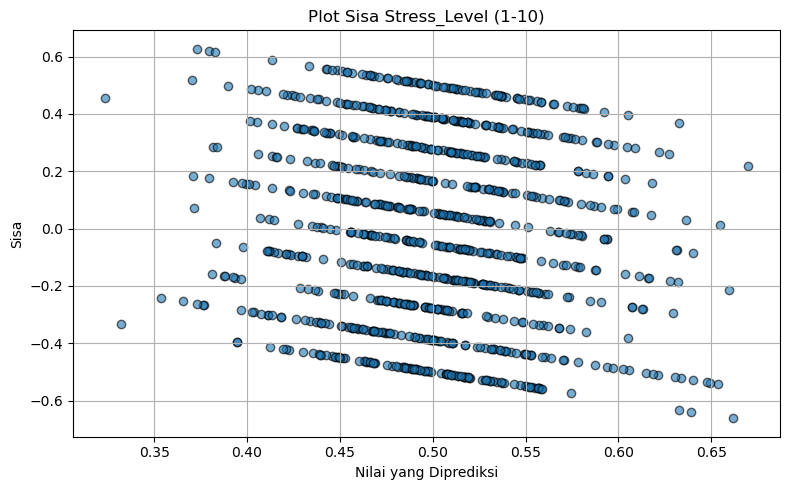

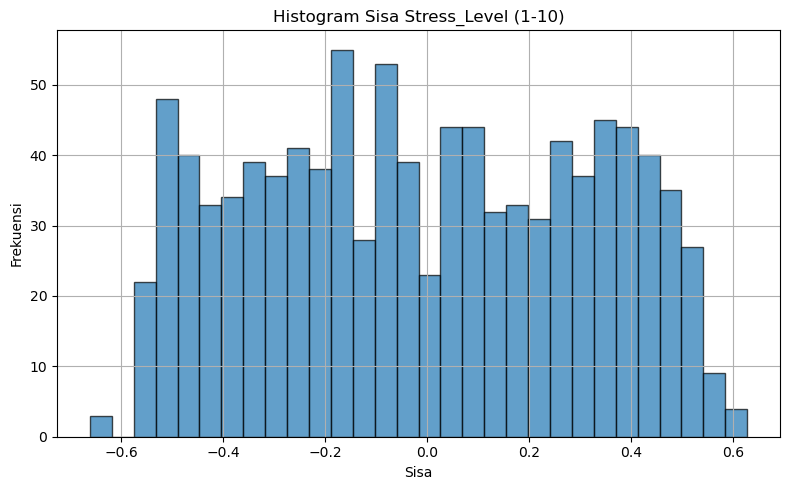

In [68]:
Random_Forest_Regressor(numeric_df,'Stress_Level (1-10)',[100,200,300,400])

Dari grafik yang ditampilkan di atas, dapat dilihat bahwa model ini masih menghasilkan jumlah error yang signifikan. Error tersebut tersebar merata di seluruh prediksi, yang menunjukkan bahwa model belum sepenuhnya dapat menggeneralisasi dengan baik terhadap data yang ada.

## **Hasil Evaluasi Antar Model**

Hasil perbandingan antara model Linear Regression, Polynomial Regression, dan Random Forest Regression menunjukkan bahwa ketiga model memiliki nilai R² negatif, yang mengindikasikan bahwa model tidak mampu menjelaskan variasi dalam data target dengan baik. Hal ini menandakan bahwa performa prediksi dari ketiga algoritma tersebut bahkan lebih buruk dibandingkan jika hanya menggunakan rata-rata target sebagai prediksi.

Selain itu, nilai RMSE berada pada rentang 0,28 hingga 0,33. Karena target sudah dinormalisasi dengan MinMaxScaler ke rentang 0 hingga 1, kesalahan ini cukup besar, yaitu hampir sepertiga dari seluruh rentang nilai. Oleh karena itu, dapat disimpulkan bahwa ketiga model tersebut belum layak digunakan untuk tugas regresi ini, dan pendekatan lain seperti feature engineering lebih lanjut, pemilihan fitur yang lebih relevan, atau penggunaan model non-regresif mungkin perlu dipertimbangkan.

Namun, di antara ketiga model tersebut, model Linear Regression menunjukkan performa paling baik, ditinjau dari nilai RMSE yang paling rendah dibandingkan dengan Polynomial Regression dan Random Forest Regression. Linear Regression menghasilkan RMSE sebesar 0.2864 untuk prediksi nilai akhir dan 0.3131 untuk prediksi tingkat stres.

Meskipun performa tersebut masih belum ideal secara keseluruhan, hasil ini menunjukkan bahwa Linear Regression relatif lebih mendekati target dibandingkan dua model lainnya, sehingga dapat dianggap sebagai model terbaik sementara untuk dataset dan fitur yang digunakan saat ini.

--- Evaluasi Total_Score ---
MAE : 0.2463
MSE : 0.0820
RMSE: 0.2864
R²  : -0.0155


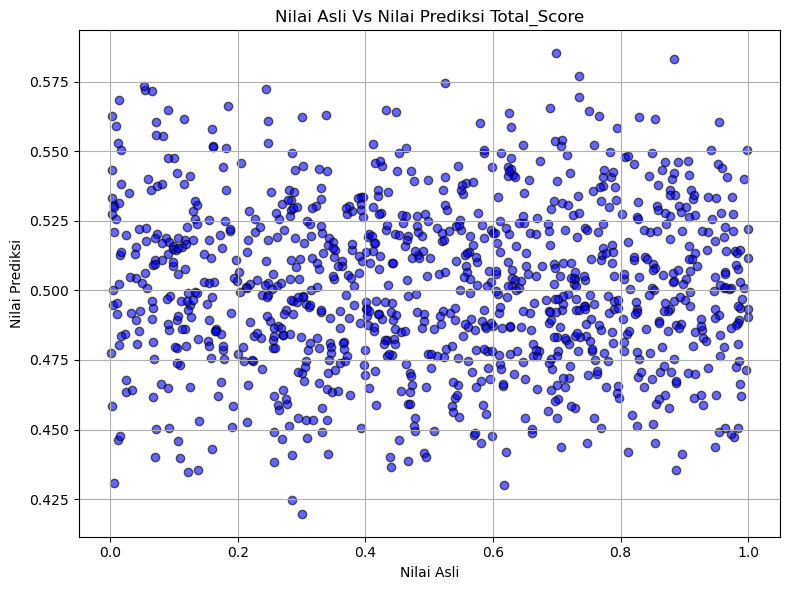

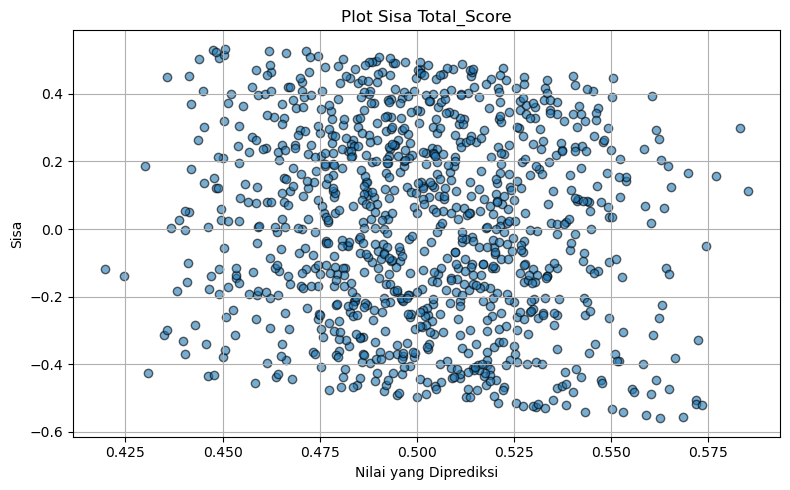

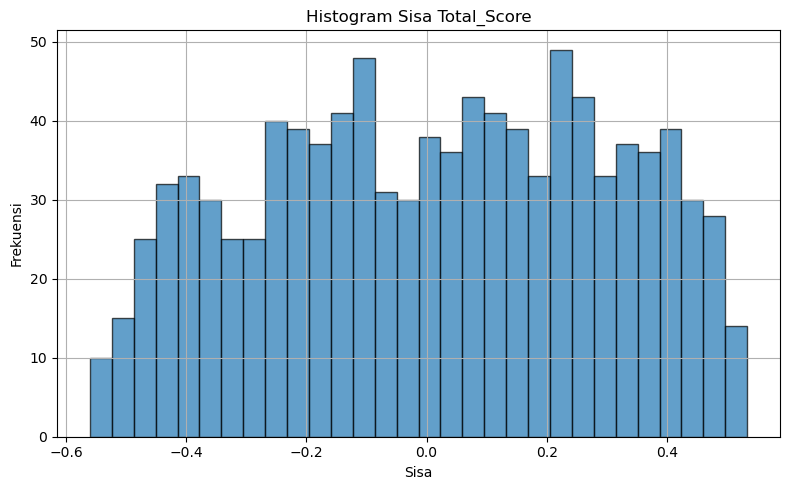

In [69]:
evaluate_linear_regression(numeric_df,'Total_Score',0.2,0,True)

--- Evaluasi Stress_Level (1-10) ---
MAE : 0.2693
MSE : 0.0980
RMSE: 0.3131
R²  : -0.0023


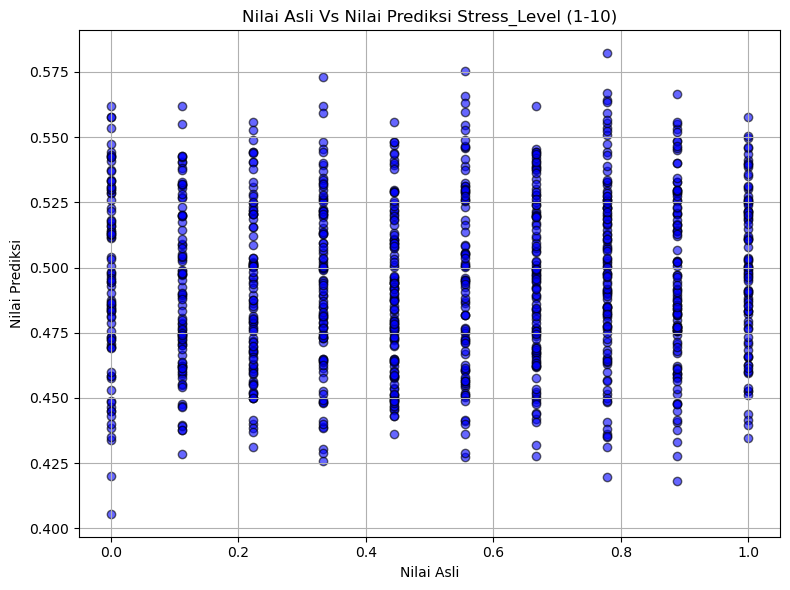

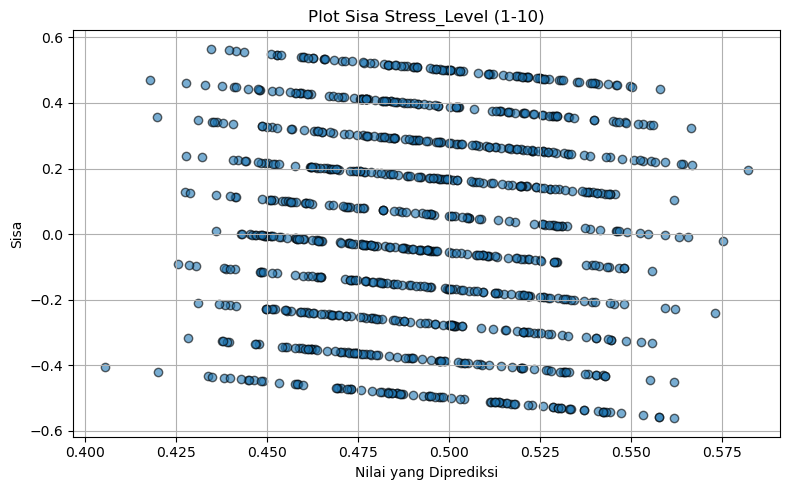

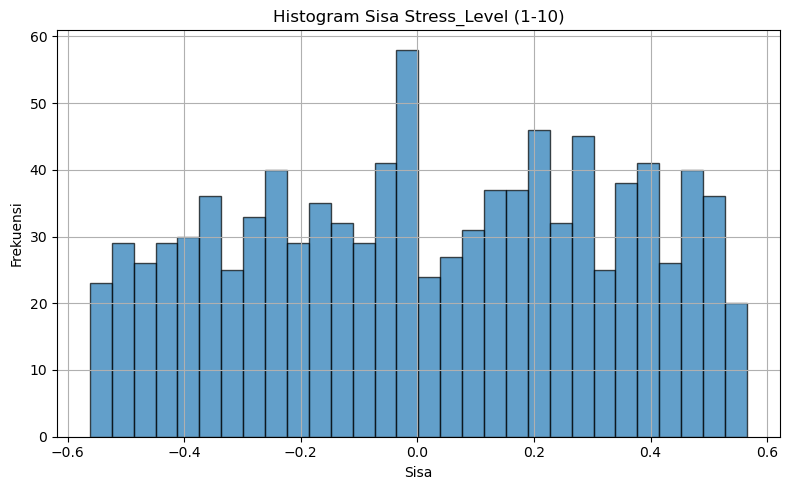

In [70]:
evaluate_linear_regression(numeric_df,'Stress_Level (1-10)',0.2,0,True)

# *Tugas 3 - Klustering*
Catatan: Sertakan juga pengukuran kinerja dan evaluasi antar model dan visualisasikan!

Tujuan utama: "Siswa akan dikelompokkan ke dalam tiga kategori utama: berkinerja tinggi, berkinerja biasa, dan sedang berjuang."

## **Preparing the data**

In [71]:
# Reduce the dimensionality of the dataset to avoid uneven clustering
pca_transform = PCA(n_components=2)
pca_dataset = pca_transform.fit_transform(main_df)

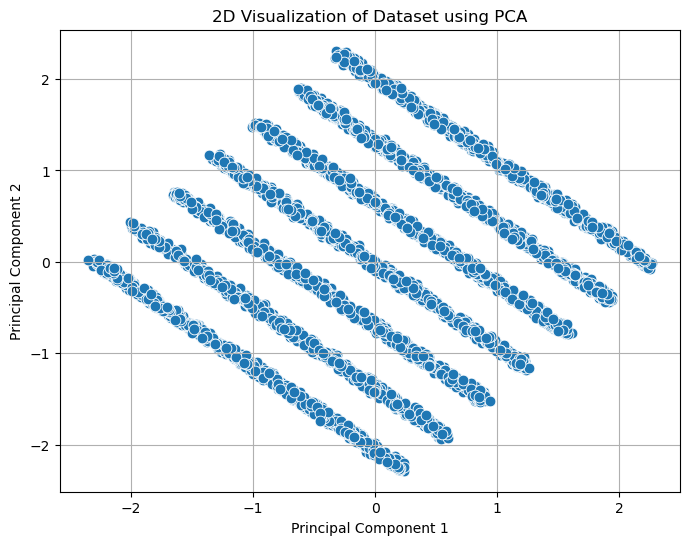

In [72]:
# Visualize the clusters
plt.figure(figsize=(8, 6))
sns.scatterplot(x=pca_dataset[:, 0], y=pca_dataset[:, 1], s=60)
plt.title("2D Visualization of Dataset using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.show()

## **Penerapan Model K-Means Clustering**

Akan dilakukan manual GridSearch dengan target mana parameter-parameter yang mampu menghasilkan nilai silhouette score tertinggi. Melalui itu, parameter-parameter tersebut akan digunakan saat pemodelan

In [73]:
# Find the best value for k and visualize it <-- GridSearchCV manually
best_k, best_score = 0, -1
sil_scores_arr = []
for k in range(2, 16):
    kmean_model = KMeans(n_clusters=k, random_state=42)
    cluster_label = kmean_model.fit_predict(pca_dataset)
    sil_score = silhouette_score(pca_dataset, cluster_label)
    sil_scores_arr.append(sil_score)
    print(f"k={k}, Silhouette Score={sil_score:.3f}")

    if sil_score > best_score:
        best_score = sil_score
        best_k = k

print(f"\nBest value for k: {best_k}")

k=2, Silhouette Score=0.353
k=3, Silhouette Score=0.388
k=4, Silhouette Score=0.412
k=5, Silhouette Score=0.387
k=6, Silhouette Score=0.360
k=7, Silhouette Score=0.372
k=8, Silhouette Score=0.368
k=9, Silhouette Score=0.375
k=10, Silhouette Score=0.369
k=11, Silhouette Score=0.365
k=12, Silhouette Score=0.371
k=13, Silhouette Score=0.383
k=14, Silhouette Score=0.392
k=15, Silhouette Score=0.387

Best value for k: 4


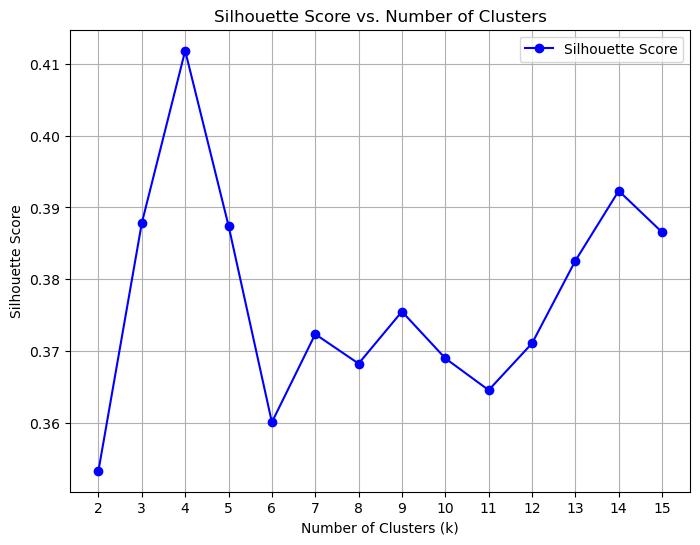

In [74]:
# Visualize the silhouette score
plt.figure(figsize=(8, 6))
plt.plot(range(2, 16), sil_scores_arr, marker='o', linestyle='-', color='b', label="Silhouette Score")
plt.title("Silhouette Score vs. Number of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 16))
plt.grid(True)
plt.legend()
plt.show()

In [75]:
KM_model = KMeans(n_clusters=best_k, random_state=42)
KM_labels = KM_model.fit_predict(pca_dataset)

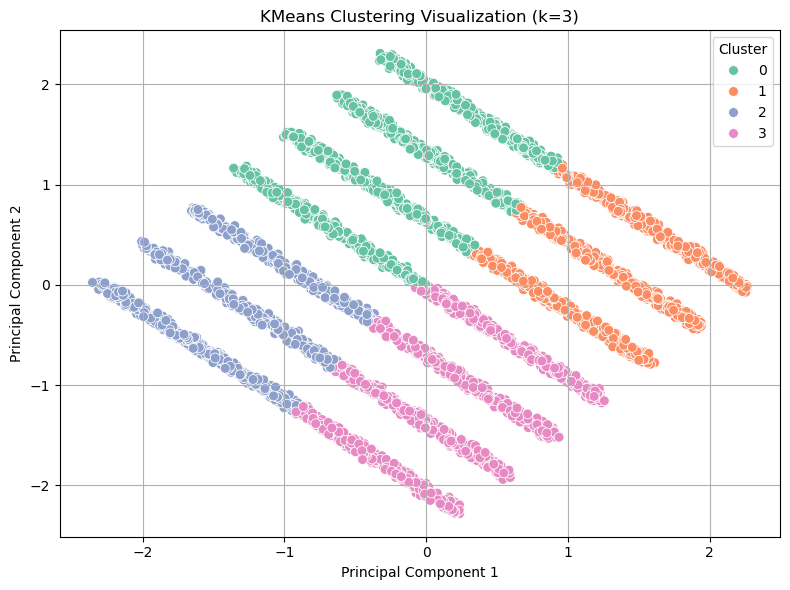

In [76]:
# Visualize the clusterings
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=pca_dataset[:, 0],
    y=pca_dataset[:, 1],
    hue=KM_labels,
    palette='Set2',
    s=50
)
plt.title("KMeans Clustering Visualization (k=3)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.grid(True)
plt.tight_layout()
plt.show()

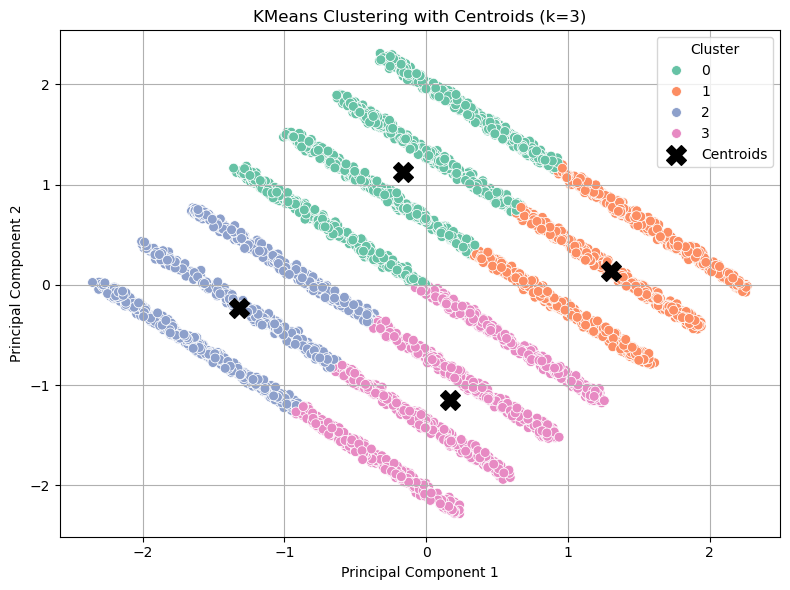

In [77]:
# Visualize the sentroids
centroids = KM_model.cluster_centers_

plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=pca_dataset[:, 0],
    y=pca_dataset[:, 1],
    hue=KM_labels,
    palette='Set2',
    s=50
)
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    s=200,
    c='black',
    marker='X',
    label='Centroids'
)
plt.title("KMeans Clustering with Centroids (k=3)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.grid(True)
plt.tight_layout()
plt.show()

Diketahui dari hasil visualisasi tersebut, clustering pada dataset tersebut kurang baik. Jika dilihat, seharusnya setiap garis pada data tersebut harus berada pada cluster yang sama. Sehingga, tidak akan menggunakan k-means clustering walau memiliki silhouette score yang cukup baik.

## **Penerapan Model DBScan**

Akan dilakukan manual GridSearch dengan target mana parameter-parameter yang mampu menghasilkan nilai silhouette score tertinggi. Melalui itu, parameter-parameter tersebut akan digunakan saat pemodelan

In [78]:
# To do silhouette score on DBSCAN
best_eps, best_min_samples = 0, 0
best_score = -1
sil_scores_arr = []

for eps in np.arange(0.1, 2, 0.1):
    for min_samp in range(3, 16):
        dbs_model = DBSCAN(eps=eps, min_samples=min_samp)
        cluster_label = dbs_model.fit_predict(pca_dataset)

        # Get the number of valid clusters (excluding noise)
        n_clusters = len(set(cluster_label)) - (1 if -1 in cluster_label else 0)

        if n_clusters >= 2:
            sil_score = silhouette_score(pca_dataset, cluster_label)
            sil_scores_arr.append((eps, min_samp, sil_score))
            print(f"eps={eps:.1f}, min_samples={min_samp}, Silhouette Score={sil_score:.3f}")

            if sil_score > best_score:
                best_score = sil_score
                best_eps = eps
                best_min_samples = min_samp
        else:
            sil_scores_arr.append((eps, min_samp, -1))  # invalid silhouette since only 1 point in cluster detected

print(f"\nBest value for eps: {best_eps} and best value for minimum sample: {best_min_samples} with Silhouette Score: {best_score:.3f}")


eps=0.1, min_samples=3, Silhouette Score=0.119
eps=0.1, min_samples=4, Silhouette Score=0.119
eps=0.1, min_samples=5, Silhouette Score=0.119
eps=0.1, min_samples=6, Silhouette Score=0.119
eps=0.1, min_samples=7, Silhouette Score=0.119
eps=0.1, min_samples=8, Silhouette Score=0.119
eps=0.1, min_samples=9, Silhouette Score=0.119
eps=0.1, min_samples=10, Silhouette Score=0.119
eps=0.1, min_samples=11, Silhouette Score=0.119
eps=0.1, min_samples=12, Silhouette Score=0.119
eps=0.1, min_samples=13, Silhouette Score=0.119
eps=0.1, min_samples=14, Silhouette Score=0.119
eps=0.1, min_samples=15, Silhouette Score=0.119
eps=0.2, min_samples=3, Silhouette Score=0.119
eps=0.2, min_samples=4, Silhouette Score=0.119
eps=0.2, min_samples=5, Silhouette Score=0.119
eps=0.2, min_samples=6, Silhouette Score=0.119
eps=0.2, min_samples=7, Silhouette Score=0.119
eps=0.2, min_samples=8, Silhouette Score=0.119
eps=0.2, min_samples=9, Silhouette Score=0.119
eps=0.2, min_samples=10, Silhouette Score=0.119
eps=0.

In [79]:
DB_model = DBSCAN(eps=best_eps, min_samples=best_min_samples)
DB_labels = DB_model.fit_predict(pca_dataset)

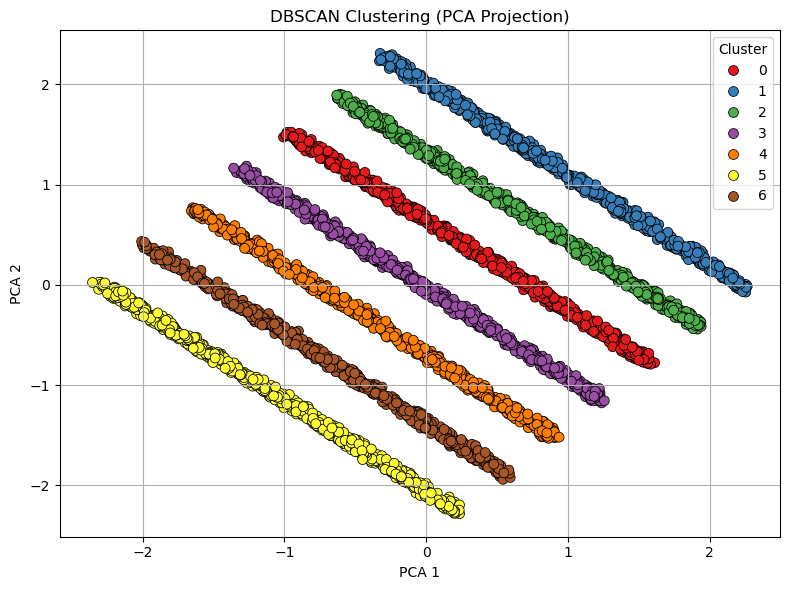

In [80]:
# Plotting
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=pca_dataset[:, 0], y=pca_dataset[:, 1],
    hue=DB_labels, palette="Set1", s=50, edgecolor='k'
)
plt.title("DBSCAN Clustering (PCA Projection)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.legend(title='Cluster', loc='best')
plt.grid(True)
plt.tight_layout()
plt.show()

Dari hasil visualisasi tersebut, setiap garis pada proyeksi PCA membentuk kluster tersendiri, sehingga DBSCAN memisahkan struktur yang terlihat dengan rapi walaupun nilai silhouette score-nya rendah.

Namun, garis-garis tersebut kemungkinan besar mencerminkan 7 nilai usia siswa (18 hingga 24 tahun), bukan kelompok performa. Age dan Study_Hours_per_Week adalah satu-satunya fitur yang distandarisasi dengan StandardScaler, sehingga keduanya memiliki varians terbesar dan mendominasi komponen PCA. Dugaan ini dapat diperiksa dengan memberi warna pada plot PCA berdasarkan kolom Age.

## **Penerapan Hierarchical Clustering**

Akan dilakukan manual GridSearch dengan target mana parameter-parameter yang mampu menghasilkan nilai silhouette score tertinggi. Melalui itu, parameter-parameter tersebut akan digunakan saat pemodelan

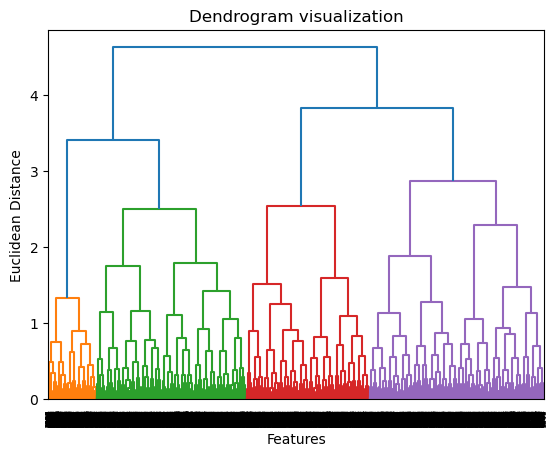

In [81]:
import scipy as sci

# Visualize the dendogram
dendrogram = sci.cluster.hierarchy.dendrogram(sci.cluster.hierarchy.linkage(pca_dataset, method='complete'))
plt.title(f"Dendrogram visualization")
plt.xlabel(f'Features')
plt.ylabel(f"Euclidean Distance")
plt.show()

Melalui hasil dendrogram tersebut, diketahui bahwa k=4 memiliki nilai yang bagus. Akan dilakukan manual GridSearch dengan target mana parameter-parameter yang mampu menghasilkan nilai silhouette score tertinggi. Melalui itu, parameter-parameter tersebut akan digunakan saat pemodelan

In [82]:
# Find the best value for k and visualize it
best_k, best_score = 0, -1
sil_scores_arr = []

for k in range(2, 16):
    agg_model = AgglomerativeClustering(n_clusters=k)
    cluster_label = agg_model.fit_predict(pca_dataset)
    sil_score = silhouette_score(pca_dataset, cluster_label)
    sil_scores_arr.append(sil_score)
    print(f"k={k}, Silhouette Score={sil_score:.3f}")

    if sil_score > best_score:
        best_score = sil_score
        best_k = k

print(f"\nBest value for k: {best_k}")

k=2, Silhouette Score=0.335
k=3, Silhouette Score=0.336
k=4, Silhouette Score=0.358
k=5, Silhouette Score=0.356
k=6, Silhouette Score=0.364
k=7, Silhouette Score=0.361
k=8, Silhouette Score=0.350
k=9, Silhouette Score=0.354
k=10, Silhouette Score=0.343
k=11, Silhouette Score=0.337
k=12, Silhouette Score=0.338
k=13, Silhouette Score=0.335
k=14, Silhouette Score=0.330
k=15, Silhouette Score=0.336

Best value for k: 6


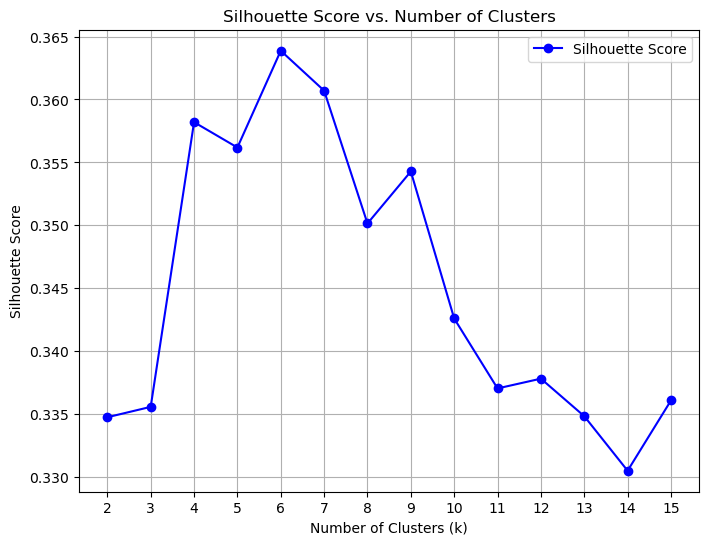

In [83]:
# Visualize the silhouette score
plt.figure(figsize=(8, 6))
plt.plot(range(2, 16), sil_scores_arr, marker='o', linestyle='-', color='b', label="Silhouette Score")
plt.title("Silhouette Score vs. Number of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 16))
plt.grid(True)
plt.legend()
plt.show()

In [84]:
HC_model = AgglomerativeClustering(n_clusters=best_k)
HC_labels = HC_model.fit_predict(pca_dataset)

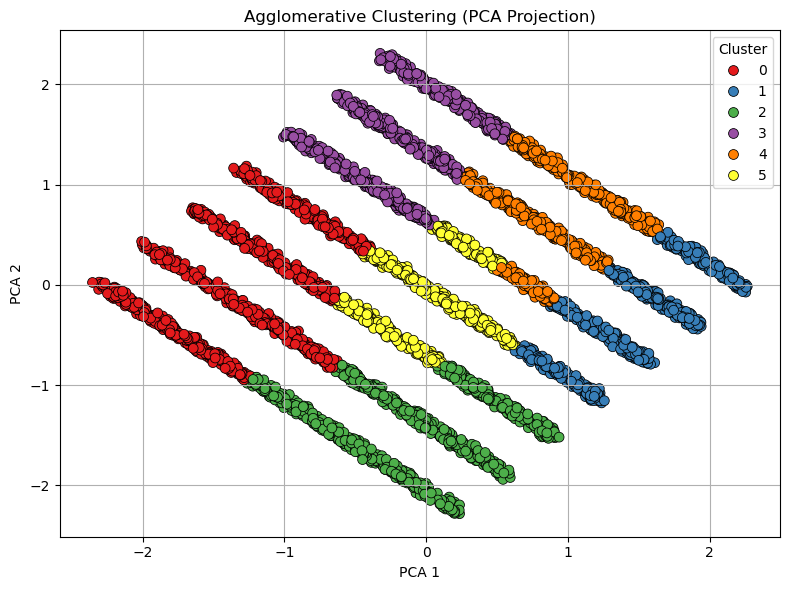

In [85]:
# Plotting
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=pca_dataset[:, 0], y=pca_dataset[:, 1],
    hue=HC_labels, palette="Set1", s=50, edgecolor='k'
)
plt.title("Agglomerative Clustering (PCA Projection)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.legend(title='Cluster', loc='best')
plt.grid(True)
plt.tight_layout()
plt.show()

Diketahui dari hasil visualisasi tersebut, clustering pada dataset tersebut kurang baik. Jika dilihat, seharusnya setiap garis pada data tersebut harus berada pada cluster yang sama. Sehingga, sama seperti k-means clustering, walau memiliki silhouette score yang cukup baik, model agglomerative clustering tidak akan digunakan dikarenakan teknik klusteringnya yang salah.

## **Hasil Evaluasi Antar Model**

Melalui grafik hasil klustering antar model, DBSCAN adalah satu-satunya model yang memisahkan setiap garis pada proyeksi PCA ke dalam kluster tersendiri dan menghasilkan 7 label. K-Means dan Agglomerative Clustering memiliki silhouette score yang lebih tinggi, tetapi keduanya memotong garis-garis tersebut.

Walaupun tujuan awal klustering adalah menghasilkan 3 kelompok (berkinerja tinggi, berkinerja biasa, dan sedang berjuang), tidak ada model yang menemukan kelompok performa tersebut. Ketujuh kluster DBSCAN kemungkinan besar mengikuti usia siswa, sehingga kolom student_cluster sebaiknya tidak ditafsirkan sebagai kelompok performa. Kolom tersebut tetap ditambahkan ke dataset untuk menandai kluster setiap siswa.

## **Implementasi model DBSCAN**

In [86]:
main_df['Student_Cluster'] = DB_labels
main_df.head()

,Age,Attendance (%),Midterm_Score,Final_Score,Assignments_Avg,Quizzes_Avg,Projects_Score,Total_Score,Study_Hours_per_Week,Stress_Level (1-10),...,Family_Income_Level_High,Family_Income_Level_Low,Family_Income_Level_Medium,Participation_Score_Low,Sleep_Hours_per_Night_Low,Parent_Education_Level_Bachelor's,Parent_Education_Level_High School,Parent_Education_Level_Master's,Parent_Education_Level_PhD,Student_Cluster
0,0.478290,0.045609,0.250584,0.297099,0.684674,0.481274,0.717944,0.121473,-1.575071,0.444444,...,0,0,1,1,1,0,1,0,0,0
1,1.483524,0.143629,0.450984,0.894965,0.354142,0.714400,0.475695,0.405844,0.418018,0.555556,...,0,1,0,1,0,0,0,1,0,1
2,1.483524,0.902981,0.129877,0.677392,0.321329,0.870819,0.842368,0.232339,0.981582,0.222222,...,1,0,0,0,0,0,1,0,0,1
3,0.980907,0.083417,0.109870,0.648383,0.937375,0.674344,0.368274,0.322393,-0.310490,0.111111,...,1,0,0,1,0,0,1,0,0,2
4,-0.024327,0.508530,0.647716,0.058853,0.428171,0.043461,0.345669,0.241345,-1.258926,0.000000,...,1,0,0,0,1,0,0,0,1,3


# *Future Works*
Catatan: Sertakan juga pengukuran kinerja     
*jika waktu memperbolehkan

Tujuan utama: "Mengidentifikasikan siswa/i yang berpotensi untuk dropout dan siswa/i yang berpotensi mengalami stress tinggi"

## **Penerapan Model Isolation Forest**

Salah satu model yang kami gunakan dalam future works ini adalah Isolation Forest. Model ini kami gunakan untuk mendeteksi anomali/outlier dari dataset ini, dengan tujuan mengidentifikasi siswa/i yang berpotensi untuk dropout dan yang mengalami stress tinggi. Kami menggunakan StandardScaler untuk menormalisasi datanya, karena Isolation Forest sensitif terhadap skala data. Kami juga mengubah datanya menjadi numerik agar bisa diproses oleh modelnya.

In [87]:
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

ISO_scaler = StandardScaler()
features = main_df.select_dtypes(include=['float64', 'int64'])
features_scaled = ISO_scaler.fit_transform(features)

n_estimators_options = [50, 100, 150, 200, 300]
max_samples_options = ['auto', 0.6, 0.8, 1.0]
contamination_options = np.arange(0.01, 0.1, 0.01)

best_score = -1
best_params = None
best_model = None

for n_estimators in n_estimators_options:
    for max_samples in max_samples_options:
        for contamination in contamination_options:
            model = IsolationForest(
                n_estimators=n_estimators,
                max_samples=max_samples,
                contamination=contamination,
                random_state=42
            )
            model.fit(features_scaled)
            labels = np.where(model.predict(features_scaled) == 1, 0, 1)
            if len(set(labels)) > 1:
                score = silhouette_score(features_scaled, labels)
                if score > best_score:
                    best_score = score
                    best_params = (n_estimators, max_samples, contamination)
                    best_model = model

print(f"\nBest Params: n_estimators={best_params[0]}, max_samples={best_params[1]}, contamination={best_params[2]}")
print(f"Best Silhouette Score: {best_score:.4f}")


Best Params: n_estimators=300, max_samples=0.8, contamination=0.01
Best Silhouette Score: 0.1091


## **Penerapan Model Local Outlier Factor (LOF)**

In [88]:
from sklearn.neighbors import LocalOutlierFactor

Dikarenakan Local Outlier Factor diharuskan datanya distandarkan semua, maka akan dilakukan StandardScaler untuk dataset tersebut.

In [89]:
# Since this model takes numerical and scaled data, we will scale the entire data
LOF_df = main_df.copy()
LOF_scaler = StandardScaler()
LOF_df_scaled = LOF_scaler.fit_transform(LOF_df)

Akan dilakukan manual GridSearch dengan target mana parameter-parameter yang mampu menghasilkan nilai silhouette score tertinggi. Melalui itu, parameter-parameter tersebut akan digunakan saat pemodelan

In [90]:
best_config = None
best_score = -1

n_neighbors_list = np.arange(10, 50, 5)
contamination_list = np.arange(0.01, 0.1, 0.01)

for n in n_neighbors_list:
    for c in contamination_list:
        lof = LocalOutlierFactor(n_neighbors=n, contamination=c)
        y_pred = lof.fit_predict(LOF_df_scaled)

        if len(np.unique(y_pred)) > 1:
            score = silhouette_score(LOF_df_scaled, y_pred)
        else:
            score = -1  # invalid silhouette score

        if score > best_score:
            best_score = score
            best_config = (n, c)

        print(f"n = {n}, c = {c:.2f}, silhouette_score = {score:.4f}")

print("\nBest parameters:")
print(f"Neighbors: {best_config[0]}")
print(f"Contamination: {best_config[1]}")
print(f"Silhouette Score: {best_score:.4f}")


n = 10, c = 0.01, silhouette_score = 0.0813
n = 10, c = 0.02, silhouette_score = 0.0746
n = 10, c = 0.03, silhouette_score = 0.0729
n = 10, c = 0.04, silhouette_score = 0.0690
n = 10, c = 0.05, silhouette_score = 0.0666
n = 10, c = 0.06, silhouette_score = 0.0651
n = 10, c = 0.07, silhouette_score = 0.0630
n = 10, c = 0.08, silhouette_score = 0.0598
n = 10, c = 0.09, silhouette_score = 0.0568
n = 15, c = 0.01, silhouette_score = 0.0876
n = 15, c = 0.02, silhouette_score = 0.0808
n = 15, c = 0.03, silhouette_score = 0.0774
n = 15, c = 0.04, silhouette_score = 0.0755
n = 15, c = 0.05, silhouette_score = 0.0732
n = 15, c = 0.06, silhouette_score = 0.0714
n = 15, c = 0.07, silhouette_score = 0.0695
n = 15, c = 0.08, silhouette_score = 0.0672
n = 15, c = 0.09, silhouette_score = 0.0647
n = 20, c = 0.01, silhouette_score = 0.0940
n = 20, c = 0.02, silhouette_score = 0.0836
n = 20, c = 0.03, silhouette_score = 0.0788
n = 20, c = 0.04, silhouette_score = 0.0779
n = 20, c = 0.05, silhouette_sco

## **Hasil Evaluasi Antar Model**

Melalui hasil dari silhouette score, kita dapat melihat bahwa isolation forest memiliki score tertinggi, yakni sekitar 0.1. Oleh karena itu, akan digunakan isolation forest untuk menentukan outlier-outlier dalam dataset agar dapat menentukan dropout yang mungkin.

Perlu dicatat bahwa dataset ini tidak memiliki label dropout yang sebenarnya, sehingga hasil ini hanya menunjukkan siswa dengan data yang tidak biasa, bukan prediksi dropout yang tervalidasi. Jumlah siswa yang ditandai (1%) juga ditentukan oleh parameter contamination yang dipilih saat tuning.

In [91]:
ISO_model = IsolationForest(n_estimators=best_params[0], max_samples=best_params[1], contamination=best_params[2], random_state=42)
y_pred = ISO_model.fit_predict(LOF_df)
main_df['Outlier'] = y_pred

In [92]:
main_df['Dropout_Predicted'] = main_df['Outlier'].apply(lambda x: 'Potential Dropout' if x == -1 else 'Normal')
main_df.drop(['Outlier'], axis=1, inplace=True)

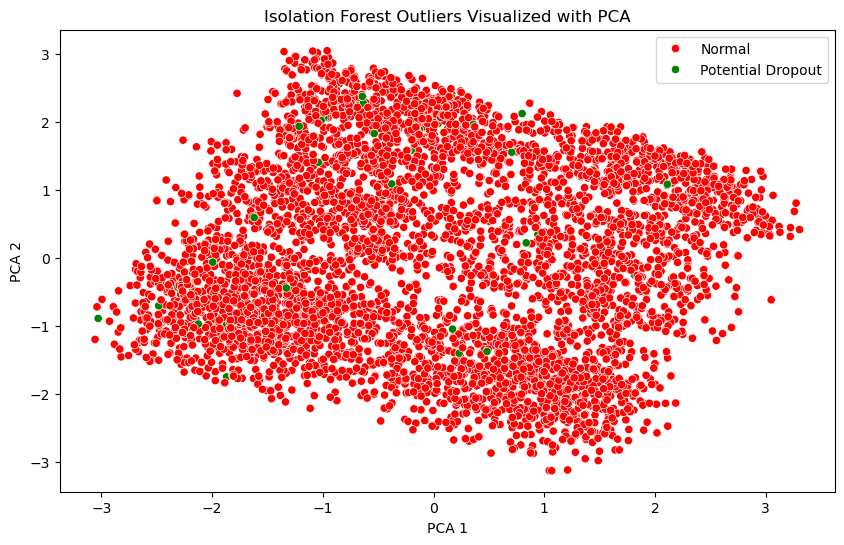

In [93]:
# Show the outlier detection using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(LOF_df_scaled)

plt.figure(figsize=(10,6))
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=main_df['Dropout_Predicted'], palette=['red', 'green'])
plt.title('Isolation Forest Outliers Visualized with PCA')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend()
plt.show()

Melalui ini, kita dapat melihat bahwa adanya outlier-outlier yang di dalam dimensi tinggi adalah suatu titik tersendiri

In [94]:
main_df['Dropout_Predicted'].value_counts()

Dropout_Predicted
Normal               4950
Potential Dropout      50
Name: count, dtype: int64

# *Kesimpulan Proyek*

1. Untuk tugas klasifikasi, tidak ada model yang lebih baik daripada tebakan acak (sekitar 25%). Random Forest memiliki rata-rata akurasi cross-validation tertinggi (25,76%) dan digunakan untuk mengisi parent_education_level yang kosong, tetapi hasil imputasi ini hampir setara dengan pelabelan acak.

2. Untuk tugas prediksi, kita menggunakan model linear regression karena memiliki nilai RMSE terkecil. Namun, nilai R² dari semua model berada di bawah nol, sehingga tidak ada model yang lebih baik daripada memprediksi nilai rata-rata. Tugas utamanya adalah melakukan prediksi untuk nilai akhir siswa dan level stress siswa.

3. Untuk tugas klustering, kita menggunakan model DBSCAN karena merupakan satu-satunya model yang memisahkan setiap garis pada proyeksi PCA. Kita mendapatkan 7 kluster dari 5000 siswa, tetapi kluster-kluster tersebut kemungkinan besar mengikuti usia siswa, bukan kelompok performa.

4. Untuk deteksi dropout, kita menggunakan isolation forest karena memiliki nilai silhouette yang lebih bagus daripada local outlier factor. Sebanyak 50 siswa (1%) ditandai sebagai potensi dropout, tetapi hasil ini belum dapat divalidasi karena tidak ada label dropout yang sebenarnya.

5. Secara keseluruhan, fitur-fitur pada dataset ini hampir tidak memiliki hubungan satu sama lain (korelasi antar fitur numerik paling besar 0,04) maupun dengan target yang diprediksi. Dataset ini kemungkinan bersifat sintetis, sehingga hasil model tidak dapat dijadikan dasar keputusan tentang siswa.